In [1]:
import os

# Core Libraries
import numpy as np
import pandas as pd
import re
import random

# PyTorch Core
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

# Keras Tokenizer (for vocab + padding)
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Scikit-learn
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.utils import resample
from sklearn.svm import SVC, LinearSVC
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
from sklearn.calibration import CalibratedClassifierCV

# Plotting
import matplotlib.pyplot as plt
from itertools import cycle

# NLP
import nltk
from nltk.stem.snowball import SnowballStemmer

# Optional: Progress Bar
from tqdm import tqdm

# Transformers (optional if using BERT later)
from transformers import AutoModel
from transformers import AutoTokenizer


C:\Users\Administrator\anaconda3\envs\pytorchCU126_py310_new\lib\site-packages\requests\__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


C:\Users\Administrator\anaconda3\envs\pytorchCU126_py310_new\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import re
from nltk.tokenize import word_tokenize

# Bengali stopwords (offline-safe)
bengali_stopwords = {
    "অতএব", "অত্যন্ত", "অথচ", "অথবা", "অধিক", "অধিকাংশ", "অনুযায়ী", "অনেক", "অনেকটা", "অনেকটাই",
    "অনেকে", "অনেকেই", "অন্তত", "অন্তর্ভুক্ত", "অন্য", "অন্যথা", "অন্যথায়", "অন্যদিকে", "অন্যান্য", "অপর",
    "অপরদিকে", "অপরাধ", "অপ্রয়োজনীয়", "অবধি", "অবশেষে", "অবশ্য", "অবশ্যই", "অবস্থান", "অর্থাত", "অর্থাৎ",
    "অল্প", "আই", "আগামী", "আগে", "আগেই", "আছে", "আজ", "আজকাল", "আদ্যন্ত", "আদ্যভাগে",
    "আধুনিক", "আপনার", "আপনি", "আবার", "আমরা", "আমাকে", "আমাদের", "আমার", "আমি", "আমিও",
    "আর", "আরও", "আশেপাশে", "আসলে", "আসা", "ই", "ইত্যাদি", "ইহা", "উচিত", "উত্তর",
    "উনি", "উপর", "উপরন্তু", "উপরে", "উল্লেখযোগ্য", "উল্লেখ্য", "এ", "এঁদের", "এঁরা", "এই",
    "এক", "একই", "একটি", "একটু", "একবার", "একাংশ", "একে", "এক্", "এখন", "এখনও",
    "এখানে", "এখানেই", "এছাড়া", "এছাড়াও", "এটা", "এটাই", "এটাও", "এটি", "এত", "এতটাই",
    "এতে", "এদিকে", "এদের", "এব", "এবং", "এবার", "এমন", "এমনকি", "এমনকী", "এমনি",
    "এর", "এরা", "এল", "এস", "এসব", "এসে", "এসেছিল", "ঐ", "ও", "ওঁদের",
    "ওঁর", "ওঁরা", "ওই", "ওকে", "ওখানে", "ওদের", "ওর", "ওরা", "কখন", "কখনও",
    "কখনো", "কত", "কবে", "কমনে", "কয়েক", "কয়েকটি", "করছে", "করছেন", "করতে", "করবে",
    "করবেন", "করলে", "করলেন", "করা", "করাই", "করায়", "করার", "করি", "করিতে", "করিয়া",
    "করিয়ে", "করে", "করেই", "করেছিলেন", "করেছে", "করেছেন", "করেন", "কাউকে", "কাছ", "কাছে",
    "কাজ", "কাজে", "কাজেই", "কারও", "কারণ", "কারণে", "কি", "কিংবা", "কিছু", "কিছুই",
    "কিন্তু", "কী", "কে", "কেউ", "কেউই", "কেখা", "কেন", "কেননা", "কেবল", "কোটি",
    "কোথাও", "কোথায়", "কোন", "কোনও", "কোনো", "ক্ষেত্রে", "কয়েক", "খুব", "গিয়ে", "গিয়েছিল",
    "গিয়েছে", "গিয়ে", "গুলি", "গেছে", "গেল", "গেলে", "গোটা", "চলছে", "চলে", "চান",
    "চায়", "চার", "চালু", "চেয়ে", "চেষ্টা", "ছাড়া", "ছাড়াও", "ছিল", "ছিলেন", "জন",
    "জনকে", "জনের", "জন্য", "জন্যওজে", "জানতে", "জানা", "জানানো", "জানায়", "জানিয়ে", "জানিয়েছে",
    "জে", "জ্নজন", "টাই", "টাকায়", "টি", "ঠিক", "ঠিকই", "তখন", "তখনই", "তখনও",
    "তত", "ততক্ষণ", "তথা", "তদুপরি", "তবু", "তবুও", "তবে", "তা", "তাঁকে", "তাঁদের",
    "তাঁর", "তাঁরা", "তাঁাহারা", "তাই", "তাও", "তাকে", "তাছাড়া", "তাতে", "তাদের", "তার",
    "তারপর", "তারা", "তারৈ", "তাহলে", "তাহা", "তাহাতে", "তাহার", "তিনঐ", "তিনি", "তিনিও",
    "তুমি", "তুলনা", "তুলনায়", "তুলে", "তেমন", "তো", "তোমার", "থাকবে", "থাকবেন", "থাকা",
    "থাকায়", "থাকে", "থাকেন", "থেকে", "থেকেই", "থেকেও", "দিকে", "দিতে", "দিন", "দিয়ে",
    "দিয়েছে", "দিয়েছেন", "দিলেন", "দু", "দুই", "দুটি", "দুটো", "দেওয়া", "দেওয়ার", "দেওয়া",
    "দেখতে", "দেখা", "দেখে", "দেন", "দেয়", "দ্বারা", "ধরা", "ধরে", "ধামার", "নতুন",
    "নয়", "না", "নাই", "নাকি", "নাগাদ", "নানা", "নিজে", "নিজেই", "নিজেদের", "নিজের",
    "নিতে", "নিম্নলিখিত", "নিয়ে", "নিয়ে", "নেই", "নেওয়া", "নেওয়ার", "নেওয়া", "নয়", "পক্ষে",
    "পর", "পরও", "পরবর্তী", "পরবর্তীতে", "পরিষ্কার", "পরিসংখ্যানগত", "পরে", "পরেই", "পরেও", "পর্যন্ত",
    "পাওয়া", "পাচ", "পারা", "পারি", "পারে", "পারেন", "পাশাপাশি", "পি", "পূর্বে", "পেয়ে",
    "পেয়্র্", "প্রতি", "প্রথম", "প্রথমে", "প্রধানত", "প্রভৃতি", "প্রযন্ত", "প্রাথমিক", "প্রায়", "প্রায়ই",
    "প্রায়", "প্রয়ন্ত", "ফলে", "ফিরে", "ফের", "বক্তব্য", "বটে", "বদলে", "বন", "বরং",
    "বর্তমানে", "বলতে", "বলল", "বললেন", "বলা", "বলে", "বলেছেন", "বলেন", "বসে", "বহু",
    "বা", "বাদে", "বার", "বি", "বিনা", "বিভিন্ন", "বিশেষ", "বিশেষ করে", "বিশেষত", "বিষয়টি",
    "বিষয়ে", "বেশ", "বেশকিছু", "বেশি", "বেশিরভাগ", "ব্যবহার", "ব্যাপারে", "ভাবে", "ভাবেই", "মতো",
    "মতোই", "মধ্যভাগে", "মধ্যে", "মধ্যেই", "মধ্যেও", "মনে", "মাঝে", "মাত্র", "মাধ্যমে", "মূলত",
    "মোট", "মোটামুটি", "মোটেই", "যখন", "যখনই", "যত", "যতক্ষণ", "যতটা", "যথা", "যথেষ্ট",
    "যদি", "যদিও", "যা", "যাঁর", "যাঁরা", "যাইহোক", "যাওয়া", "যাওয়ার", "যাওয়া", "যাকে",
    "যাচ্ছে", "যাতে", "যাদের", "যান", "যাবে", "যায়", "যার", "যারা", "যিনি", "যে",
    "যেকোনো", "যেখানে", "যেতে", "যেন", "যেমন", "র", "রকম", "রয়েছে", "রাখা", "রেখে",
    "লক্ষ", "লক্ষ্য", "শুধু", "শুরু", "সংক্ষেপে", "সংশ্লিষ্ট", "সঙ্গে", "সঙ্গেও", "সদৃশ", "সব",
    "সবার", "সমস্ত", "সম্পর্কিত", "সম্প্রতি", "সম্ভবত", "সহ", "সহিত", "সাথে", "সাধারণ", "সাধারণত",
    "সামগ্রিক", "সামগ্রিকভাবে", "সামনে", "সি", "সুতরাং", "সে", "সেই", "সেখান", "সেখানে", "সেটা",
    "সেটাই", "সেটাও", "সেটি", "স্পষ্ট", "স্বয়ং", "স্বাভাবিক", "হইতে", "হইবে", "হইয়া", "হওয়া",
    "হওয়ায়", "হওয়ার", "হচ্ছে", "হত", "হতে", "হতেই", "হন", "হবে", "হবেন", "হয়",
    "হয়তো", "হয়নি", "হয়ে", "হয়েই", "হয়েছিল", "হয়েছিলো", "হয়েছে", "হয়েছেন", "হল", "হলে",
    "হলেই", "হলেও", "হলো", "হাজার", "হিসাবে", "হৈলে", "হোক", "হয়"
}

bn_sw = bengali_stopwords

# Rule-based pseudo stemmer
def basic_bengali_stemmer(word):
    suffixes = [
        'গুলোকে', 'দেরকে', 'গুলোয়', 'গুলোতে', 'গুলো', 'গুলি', 'দের', 'দেরকে', 
        'টাকে', 'টিতে', 'টায়', 'টা', 'টি', 'কে', 'তে', 'তা', 'ের', 'েন', 'ছি', 'ছিল', 
        'বেন', 'েছ', 'ে', 'রা', 'য়', 'থেকে', 'রে', 'য়ের', 'য়েও', 'তেই', 'টার', 'টারও', 
        'টারওকে', 'টারই', 'টারইকে', 'টারইয়েও', 'ছিলাম', 'ছিলেন', 'বো', 'বে', 'তেছি', 
        'ছিলো', 'তেও', 'তাই', 'তো', 'তাম', 'তেছে', 'ছেন', 'লেন', 'ল', 'র', 'এর', 'রই'
    ]
    for suffix in suffixes:
        if word.endswith(suffix) and len(word) > len(suffix) + 1:
            return word[:-len(suffix)]
    return word

# Cleaning functions
def remove_url(text):
    return re.sub(r"(?:\@|https?\://)\S+", "", text) if isinstance(text, str) else ''

def remove_numbers(text):
    return re.sub(r'\d+', '', text) if isinstance(text, str) else ''

def remove_english(text):
    return re.sub(r'[a-z]', '', text) if isinstance(text, str) else ''

def remove_short_words(text, min_len=2):
    if not isinstance(text, str):
        return ''
    return ' '.join([word for word in text.split() if len(word) >= min_len])

def remove_repeated_punctuation(text):
    return re.sub(r'[\?\.\!\।]+(?=[\?\.\!\।])', '', text) if isinstance(text, str) else ''

def remove_extra_whitespace(text):
    return ' '.join(text.split()) if isinstance(text, str) else ''

def remove_dari(text):
    return re.sub(r'।', '', text) if isinstance(text, str) else ''

def remove_bengali_stopwords(text):
    if not isinstance(text, str):
        return ''
    return ' '.join([word for word in text.split() if word not in bengali_stopwords])

# Final cleaner
def clean_comment(text):
    if not isinstance(text, str):
        return ''
    text = text.lower()
    text = remove_url(text)
    text = remove_english(text)
    text = remove_dari(text)
    text = remove_numbers(text)
    text = remove_short_words(text)
    text = remove_repeated_punctuation(text)
    text = remove_extra_whitespace(text)
    words = text.split()
    # Remove stopwords and apply stemming
    cleaned = [basic_bengali_stemmer(word) for word in words if word not in bengali_stopwords]
    return ' '.join(cleaned)

label_encoder = LabelEncoder()

In [3]:
# Define positive Bengali words
positive_words = {
    "অংশগ্রহণমূলক", "অগ্রসর", "অতিথিপরায়ণ", "অতুলনীয়", "অত্যন্ত ভালো", "অধ্যবসায়ী", "অনন্য", "অনবদ্য", "অনিন্দ্য", "অনুপ্রেরণাদায়ী",
    "অনুরণিত", "অপূর্ব", "অবিরাম", "অবিশ্বাস্য", "অভিজ্ঞ", "অভিনন্দন", "অমায়িক", "অর্জন", "অর্জনমূলক", "অর্থবহ অর্জন",
    "অসাধারণ", "অ্যাওয়ার্ডপ্রাপ্ত", "আওয়াজময়", "আকর্ষণীয়", "আঙ্গিক শিল্প", "আত্মঅনুপ্রেরণা", "আত্মবিশ্বাসী", "আত্মমুগ্ধ", "আদর্শবান", "আদান-প্রদান",
    "আধিপত্য", "আধুনিক", "আনন্দ প্রদায়ক", "আনন্দদায়ক", "আনন্দময়", "আন্তঃসামাজিক", "আন্তরিক", "আন্তরিক সমর্থন", "আন্তর্জাতিক খ্যাতিপ্রাপ্ত", "আবেগপ্রবণ",
    "আবেদ্য", "আরোগ্য", "আলোকচিত্রণ", "আলোকিত", "আলোকিত ধারণা", "আশা জাগানো", "আশার আলো", "আশ্চর্যজনক", "উচ্ছ্বাস", "উজ্জীবিত",
    "উজ্জ্বল", "উত্তম", "উত্সাহজনক", "উদার", "উদার বিশ্বাস", "উদারপন্থী", "উদ্দীপনাময়", "উদ্দীপনার ফল", "উদ্দীপ্ত", "উদ্দেশ্যপূরণ",
    "উদ্বুদ্ধ", "উদ্ভাবনী", "উদ্যমী", "উদ্যোক্তা মনের", "উন্নত", "উন্নতির পথ", "উন্নয়নমুখী", "উপাধিসম্পন্ন", "উল্লসিত", "উৎকর্ষ",
    "উৎসাহজনক বক্তব্য", "উৎসাহী", "একতাবদ্ধ", "একাগ্রতা", "একান্ত ভালো", "একেবারে অসাধারণ", "এগিয়ে চিন্তা", "এমনিষ্ট", "ঐতিহ্যবাহী", "ওয়েভীয়",
    "কবিতাময়", "কর্পোরেট", "কর্মঠ", "কর্মসতর্ক", "কল্পনাপ্রবণ", "কল্যাণকামী", "কাব্যবোধ", "কার্যকর", "কৃতজ্ঞতা", "ক্ষমতাশালী",
    "খাঁটি", "খুশি", "গর্বিত", "গীতবোধ", "গুণগত", "গৌরবজনক", "চতুর", "চমৎকার", "চিত্তাকর্ষক", "চিত্রকর",
    "চিত্রাঙ্কন", "চেয়ারপ্রাপ্ত", "জয় হোক", "জয়ী", "টুকরো টুকরো চিন্তা", "দক্ষতা", "দয়ালু", "দর্শনীয়", "দায়িত্বশীল", "দারুণ",
    "দারুণ কাজ", "দার্শনিক চিন্তা", "দায়িত্ববান", "দীপ্ত", "দূরদর্শী", "দৃঢ়", "দৃঢ়প্রতিজ্ঞ", "দৃষ্টিনন্দন", "দৃষ্টিসম্পন্ন", "ধারাবাহিক উন্নতি",
    "নকশাময়", "নম্র", "নম্রমনা", "নাট্যগুণ", "নান্দনিক", "নিখুঁত", "নিবেদিত", "নির্দ্বিধায়", "নির্ভরযোগ্য", "নির্ভীক",
    "নিশ্চিত", "নিষ্কলুষ", "নিষ্ঠাবান", "নীতিবান", "নৃত্যগতি", "নৈর্ব্যক্তিক", "ন্যায়পরায়ণ", "পরিকল্পনাময়", "পরিচালন দক্ষ", "পরিপূর্ণ",
    "পরিবারমুখী", "পরিশ্রমী", "পরোপকারী", "পারদর্শী", "পারস্পরিক", "প্রকাশক্ষম", "প্রজ্ঞাপূর্ণ", "প্রজ্ঞাবান", "প্রতিযোগিতামূলক", "প্রভাতরূপ",
    "প্রভাবশালী", "প্রযুক্তিগত অগ্রগতি", "প্রশংসনীয়", "প্রশংসানীয়", "প্রশস্ত", "প্রশান্ত", "প্রশান্তি", "প্রাণবন্ত", "প্রিয়জনবান্ধব", "প্রেরণাদায়ক",
    "প্রেরণাময়", "ফলপ্রসূ", "বন্ধনমূলক", "বন্ধুত্বমূলক", "বন্ধুত্বসূচক", "বরণীয়", "বর্ণাঢ্য", "বস্তুনিষ্ঠ", "বাঁচার আনন্দ", "বাকশিল্প",
    "বিখ্যাত", "বিনয়ী", "বিশুদ্ধ মনোভাব", "বিশ্বস্ত", "বিশ্বের মান", "বিশ্লেষণী", "বুদ্ধিমান", "বেড়ে চলা", "বৈচিত্র্যবদ্ধ", "বৈজ্ঞানিক অর্জন",
    "ব্যঞ্জনাময়", "ব্যতিক্রমী", "ব্যাপক মনোভাব", "ভদ্র", "ভরসাযোগ্য", "ভলোমুলক", "ভাবনাময়", "ভালোবাসা", "ভাষাগত দখল", "মজাদার",
    "মঞ্চবোধ", "মধুর", "মধুর সম্পর্ক", "মননশীল", "মনোভোগ", "মনোমুগ্ধকর", "মনোযোগী", "মহান", "মহৎ", "মাধুর্যময়",
    "মানব বন্ধন", "মানবিক", "মানসম্পন্ন", "মার্জিত", "মিষ্টি", "মুক্তমনা", "মুগ্ধ", "মুদ্রণশিল্প", "মূল্যবান সাফল্য", "মেধাবী",
    "মৈত্রী", "যথার্থ", "যোগাযোগযোগ্য", "রঙ্গভঙ্গিমাপূর্ণ", "রহস্যময়", "রীতিনির্মাতা", "রূপময়", "রূপসজ্জা", "রূপান্তরকামী", "রেকর্ড-নির্মাতা",
    "লক্ষ্যমুখী", "লাবণ্য", "লোভনীয়", "শক্তিমান", "শক্তিশালী", "শব্দকল্পনা", "শব্দরহস্য", "শান্তিপূর্ণ", "শান্তিপূর্ণ সমঝোতা", "শিল্পগ্রন্থ",
    "শৃঙ্খলার", "শ্রদ্ধা", "শ্রদ্ধাবান্দব", "শ্রদ্ধাভাজন", "শ্রদ্ধাশীল", "শ্রদ্ধেয়", "শ্রেষ্ঠ", "শ্রেষ্ঠত্ব", "সংগীতাত্মক", "সক্রিয়",
    "সখ্য", "সতেজতা", "সত্য", "সদাচার", "সদ্ব্যবহার", "সদ্যাগত", "সন্মানজনক", "সন্মিলিত", "সমন্বিত শিল্প", "সমবেদনা",
    "সমালোচনামূলক চিন্তা", "সমৃদ্ধ", "সম্প্রকাশিত", "সম্প্রসারিত", "সম্ভাবনাময়", "সম্মাননীয়", "সম্মানিত", "সর্বজনীন", "সহকর্মীপ্রিয়", "সহজ",
    "সহনশীল", "সহনশীল আলোচনায়", "সহমতান্বিত", "সহমর্মী", "সহানুভূতিপূর্ণ", "সহানুভূতির প্রকাশ", "সহানুভূতিশীল", "সহায়ক", "সহিত", "সাফল্যময়",
    "সাবলীল", "সামাজিক", "সার্টিফাইড", "সাহসী", "সাহসী পদক্ষেপ", "সাহসের উদাহরণ", "সাহিত্যবোধ", "সুনির্দিষ্ট", "সুন্দর", "সুর-সুরে",
    "সুরুচিপূর্ণ", "সুশাসিত", "সৃজনপট", "সৃজনশীল", "সৃজনশীলতা", "সৃষ্টিশীল", "সেরা", "সেরা পজিশন", "সৌজন্যবতী", "সৌজন্যমূলক",
    "সৌন্দর্য", "সৌন্দর্যনিরূপণ", "সৌম্য", "সৌম্যবাচন", "স্থিতিশীল", "স্নিগ্ধ", "স্পন্দনশীল", "স্পষ্টবাদী", "স্ব-উন্নতি", "স্বপ্নপালক",
    "স্বপ্নিল", "স্বয়ংসম্পূর্ণতা", "স্বর্ণালী", "স্বাস্থ্যকর", "স্বীকৃত", "স্মরণীয়", "সৎ", "হংস", "হালকা", "হিরণ্ময়",
    "হীরক", "হৃদয়স্পর্শী", "তুমি অবিস্মরণীয়।", "তুমি অসাধারণ।", "তুমি আশ্চর্যকর!", "তুমি উদার ও সহানুভূতিশীল।", "তুমি একজন প্রকৃত নেতা।", "তুমি একাগ্র।", "তুমি চমৎকার বন্ধু।", "তুমি দায়িত্বশীল।",
    "তুমি দারুণভাবে উন্নত করেছো।", "তুমি দৃষ্টান্ত!", "তুমি পরিপূর্ণ।", "তুমি বিতর্কশীল নয়।", "তুমি বিশ্বস্ত।", "তুমি ব্যবহারিক ও চতুর।", "তুমি ভাল উদাহরণ।", "তুমি মানবদরদী।", "তুমি মেধাবী।", "তুমি শান্তিপূর্ণ।",
    "তুমি সংহত ও মেধাবী।", "তুমি সকলের প্রিয়।", "তুমি সত্যিই মূল্যবান।", "তুমি সর্বদা উন্নতিসাধনকারী।", "তুমি সাহসী।", "তুমি সুন্দরভাবে সংহত।", "তুমি স্থিরমনা।", "তোমার অনুগ্রহ অপরিসীম।", "তোমার অভিব্যক্তি প্রাসঙ্গিক।", "তোমার আচরণ নম্র।",
    "তোমার আচরণ প্রশংসনীয়।", "তোমার উদ্যোগ ফলপ্রসূ।", "তোমার উপদেশ মূল্যবান।", "তোমার উপস্থিতি শ্রেষ্ঠ।", "তোমার উপস্থিতিও মূল্যবান।", "তোমার কথা স্পষ্ট।", "তোমার চিন্তা অনুপ্রেরণীয়।", "তোমার দৃষ্টি ভিন্ন।", "তোমার নেতৃত্ব প্রশংসিত।", "তোমার পরামর্শ গ্রহণযোগ্য।",
    "তোমার পরিশ্রম ফলপ্রসূ।", "তোমার প্রচেষ্টা প্রশংসনীয়।", "তোমার প্রেরণা অসাধারণ।", "তোমার মতো কেউ আর নেই।", "তোমার মনোযোগ অদ্ভুত।", "তোমার শক্তি অনন্য।", "তোমার সাহস প্রশংসনীয়।", "তোমার সৃজনশীলতা আনন্দদায়ক।", "তোমার সৃষ্টি চমৎকার।", "তোমার স্পর্ধা বৃথা নয়।",
    "তোমার হাসি অনুপ্রেরণা।", "ভালো কাজ করেছো!"
}
negative_words = {
    "অধম", "অপকর্মী", "অপদার্থ", "অপমান", "অশ্লীল", "অসভ্য", "অস্পৃশ্য", "আবাল চোদা", "উপ্তা কইরা চুদমু", "উপ্তা কইরা চুদা দিমু"
    "উষ্টা খা", "এক কানে হোল ভইরা আরেক করমু", "কম্বক্ত", "কাঠ্ঠির বেট্যা", "কান্দে ফালাইয়া তর মায়েরে চুদি", "কাফের", "কুত্তা", "কুত্তাচোদা", "কুত্তার পুকটি চাটামু", "কুত্তার বাচ্চা"
    "কুত্তার বাচ্ছা", "কুত্তার হোল", "কুলটা", "খবিশ", "খবিশ চোদা", "খাঙ্কিরপোলা", "খানকি", "খান্কি মাগি", "খান্কি মাগির পোলা", "খারাপ মন্তব্য"
    "খুন", "খুন করব", "খ্রিস্টান কুকুর", "গলা কাটব", "গাধা", "গালি", "গাড় মারা খা", "গুদা", "গুদির ব্যাটা", "গুদের বাল"
    "গুয়ার ভিতরে ভইড়া দিমু", "গেলমান", "গোলাম আযম", "গো আর জুতা", "গোয়ালার বাচ্চা", "গোলাম আযম", "গোস্তের লাঠি সাটামু", "ঘর থেকে তাড়াব", "ঘৃণা", "চতুরচোর"
    "চামার", "চামড়া ছুইল্লা লবণ লাগামু", "চুতমারানি", "চুতমারানীর পোলা", "চুদনা মাগী", "চুদমু", "চুদানির পো", "চুদির পোলা", "চুদির ভাই", "চোখ তুলব"
    "চোদ", "চোদনা", "চোদা", "চোর", "ছি ছি ছি", "জং ধরা লোহা দিয়া পাকিস্তানের মানচিত্র বানাই্য়া তোদের পিছন দিয়া ঢুকামু", "জঘন্য", "জল্লাদ", "জাত খারাপ", "জাতিচ্যুত"
    "জীবন নষ্ট করব", "জ্যান্ত পুড়িয়ে মারব", "টিটকারি", "টেংরি ভাইংগা হাতে ধরায়া দিমু", "ঠ্যাঁঙ কাইট্টা পুটকি দা ভইরা দুম!", "তর ধন দিয়া মাটি খুড়ুম", "তর পুটকিত ধান ছড়াইয়া চড়ুই দিয়া খাওয়ামু", "তর বাপপের হোল তর বউয়ের ভোদাতে", "তর বাপের ধন দিয়া ডাংগুলি খেলুম", "তর বাপের পুটকির ফুটা দিয়া কাডল ঢুকামু"
    "তর বাপের বিচি বেইচা কটকটি খামু", "তর বাপের হোগা দিয়া ট্রেন ভইরা দিমু", "তর বৌয়ের ভোদায় মাগুর মাছ চাষ করুম", "তর ভোদায় বিলাই হ্যাচড়া", "তর মার ভোদায়", "তর মায়রে চুদি", "তর মায়রে বাপ", "তর মায়ের ঐখানে বিছাতু পাতা", "তর মায়ের ভুদাতে পোকা", "তর মায়ের ভোদা ছিল্লা লবণ লাগায় দিমু"
    "তর মায়ের ভোদা বোম্বাই মরিচ দিয়া চুদামু", "তর মায়ের ভোদা শিরিষ কাগজ দিয়া ঘইষা দিমু", "তর মায়ের ভোদায় আউটপুট", "তর মায়েরে চিচিং ফাক", "তর হোগায় ইনপুট", "তরে গোআ দিয়া চুদামু", "তিনকোনা", "তোগোর ধোন টাইনা তোগোর পিছন দিয়া ঢুকামু", "তোগোরে ফাসিতে লটকাইয়া চুদমু", "তোর জাঙ্গীয়া খুইল্যা আগুন লাগায় দিমু"
    "তোর নাকে হাইগ্যা দিমু", "তোর বউয়ের মুসলমানি দিমু", "তোর বাপ গাইড়্যা", "তোর বাপে তোর নানা", "তোর বাপের ব্যাটা", "তোর হউরিরে ডিগবাজী", "তোর হোল ভাজি কইরা তোরেই খাওয়ামু", "দলিত কুকুর", "ধরাশায়ী করব", "ধর্ম ছাড়"
    "ধর্ম যুদ্ধ", "ধর্মদ্রোহী", "ধর্মান্তর", "ধর্মের অপমান", "ধর্মের নামে হিংসা", "ধর্মের শত্রু", "ধর্ষক", "ধর্ষণ", "ধোন", "ধোন কাইট্টা কুত্তা দিয়া খাওয়ামু"
    "ধোনের বাল", "নটি", "নটি মাগি", "নটি মাগির ঝি", "নটি মাগির পোলা", "নরকগামী", "নরাধম", "নষ্ট", "নাটকির পো", "নাস্তিক"
    "নিচ", "নিজামী চোদা", "নিজামীর গোয়ার কৃমি", "নিবীর্জ", "নীচ জাত", "নীজামী", "পাজি", "পাথর মারব", "পাপী", "পাষণ্ড"
    "পিটিয়ে মারব", "পুকটি", "পুকটি মারা খা", "পুক্টি", "পুটকি", "পুটকিতে বাশ দিমু", "পূজা বন্ধ", "পেল", "ফাটা কন্ডমের ফসল", "বটই"
    "বদমাশ", "বদমায়েশ", "বস্তা", "বাইনচোদ", "বানচোত", "বাপের আগে বাল ফালায়", "বারবাতারি", "বাল", "বাল ছাল", "বাল ফালাইয়া আটি বান"
    "বাল ফালায়া আটিঁ বান্ধা", "বাল ফালায়া খালে নামানো", "বালি দিয়া চুদমু তরে খাঙ্কি মাগী!", "বালে বালে গিট্টু", "বালের রয়েল বেঙ্গল উকুন", "বুদ্ধি নষ্ট", "বেশ্যা", "বেশ্যা মাগী", "বেশ্যার পুত্র", "বোকা আচোদা"
    "বোকাচোদা", "বোমা মারব", "বৌদ্ধ নষ্ট", "ভইরা দিমু", "ভাতার চুদা", "ভুদার বেটা", "ভুস্কি মাগির পোলা", "ভেড়াচ্চোদা", "ভৈরব মাগী", "ভোগ"
    "ভোদাই", "ভোদার বাল", "মইত্যা নিজামী", "মজবাশার", "মন্দির ভাঙো", "মর বাচ্চা", "মসজিদ ধ্বংস", "মহাবুবস্", "মাই চুষ", "মাইগ্যা"
    "মাউড়া চোদা", "মাগি", "মাগিবাজ", "মাঙ্গির পুত", "মাঙ্গের নাতি", "মাঙ্গের পোলা", "মাথা ফাটব", "মাদার চোদ", "মারধর", "মাসিকের ত্যানা"
    "মাহফুজ সাহেব", "মীরজাফর", "মুখে থু", "মুজাহিদের বউ", "মুসলিম কুকুর", "মূর্খ", "মেয়েলি গালি", "মেরে ফেলব", "মোবাইল ভাইব্রেশন কইরা তুর পুকটিতে ভরবো", "যৌন"
    "রক্ত ঝরাব", "রাঁড়", "লটির পো", "লটির বেটা", "লাত্থায় তর মার আনরেজিস্টার্ড শ্বশুরবাড়ী ফাকিস্তান পাঠায় দিমু", "লাথ্থি দিমু", "লান্ড চুষ", "লেওরা", "ল্যাউড়ার পুত", "ল্যাদানী"
    "শত্রু", "শয়তান", "শাউয়া", "শালা", "শালার পো শালা", "শুয়োরের বাচ্চা", "সুদখোর", "স্ত্রীজাত", "হত্যা", "হত্যাকারী"
    "হরিজন", "হাঁড়িচ্যাটা", "হাইগ্যা", "হাউয়ার নাতি", "হাউয়ার পো", "হাড় ভাঙব", "হাতির ল্যাওড়া দিয়া তর মায়েরে চুদুম", "হারামখোর", "হারামজাদা", "হারামি"
    "হারামির বাচ্চা", "হালা ল্যাওড়া চোদা", "হিটলার", "হিন্দু কুকুর", "হুমুন্দির পুত", "হোগা চাটা", "হোগার ভিতরে ভইড়া দিমু", "হোল", "হোল টাইনা পুকটিতে ভর", "হোলচাটা"
    "হোলের চুলকানী"
}

# Function to check for positive words
def is_positive(comment):
    return any(word in comment for word in positive_words)

# Function to check for negative words
def is_negative(comment):
    return any(word in comment for word in negative_words)

# Custom Methods
def classify_sentiment(row):
    if row['category'] == 1:
        return 'negative'
    elif is_negative(row['comment']):
        return 'negative'
    elif is_positive(row['comment']):
        return 'positive'
    else:
        return 'neutral'

# Load existing datasets
# --- Dataset 1: bangla_online_comments_dataset.csv ---
df1 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/bangla_online_comments_dataset.csv')
df1 = df1.rename(columns={'comment': 'comment', 'label': 'category'})[['comment', 'category']]
df1['comment'] = df1['comment'].astype(str).fillna('').str.strip()

df1['is_positive'] = df1['comment'].apply(is_positive)
df1['is_negative'] = df1['comment'].apply(is_negative)

conditions = [
    (df1['category'] == 'not bully') & df1['is_positive'],
    (df1['category'] == 'not bully') & ~df1['is_positive'],
    (df1['category'].isin(['troll', 'religious'])) & ~df1['is_negative']
]
choices = [
    'positive',  # Condition 1
    'neutral',   # Condition 2
    'neutral'    # Condition 3
]
df1['sentiment'] = np.select(conditions, choices, default='negative')  # Fallback to negative
df1 = df1[df1['sentiment'].isin(['positive', 'negative'])].reset_index(drop=True)

# --- Dataset 2: Bengali hate speech.csv ---
df2 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/Bengali hate speech.csv')
df2 = df2[['sentence', 'hate']]
df2 = df2.rename(columns={'sentence': 'comment', 'hate': 'category'})[['comment', 'category']]
df2['comment'] = df2['comment'].astype(str).fillna('').str.strip()

# Apply classification
df2['sentiment'] = df2.apply(classify_sentiment, axis=1)
df2 = df2[df2['sentiment'].isin(['positive', 'negative'])].reset_index(drop=True)

# --- Dataset 3: bdsh_train.csv ---
df3 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/bdsh_train.csv')
df3 = df3.rename(columns={
    'sentence': 'comment',
    'hate speech': 'category'
})[['comment', 'category']]
df3['comment'] = df3['comment'].astype(str).fillna('').str.strip()

# Apply classification
df3['sentiment'] = df3.apply(classify_sentiment, axis=1)
df3 = df3[df3['sentiment'].isin(['positive', 'negative'])].reset_index(drop=True)

# Load SentNoB dataset
df4 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/SentNoB_train.csv')
df4 = df4.rename(columns={
    'Data': 'comment',
    'Label': 'category'
})[['comment', 'category']]

df4['comment'] = df4['comment'].astype(str).fillna('').str.strip()

# Map numerical labels to sentiments
label_mapping = {0: 'neutral', 1: 'positive', 2: 'negative'}
df4['sentiment'] = df4['category'].map(label_mapping)
df4 = df4[df4['sentiment'].isin(['positive', 'negative'])].reset_index(drop=True)

# Load the Saqib dataset
df5 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/saqib-data-merged.csv')
df5 = df5.rename(columns={
    'text': 'comment',
    'sentiment': 'sentiment'
})[['comment', 'sentiment']]

df5['comment'] = df5['comment'].astype(str).fillna('').str.strip()
df5 = df5[df5['sentiment'].isin(['positive', 'negative'])].reset_index(drop=True)

# --- Dataset 6: collected.csv ---
df6 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/collected.csv')
df6 = df6.rename(columns={
    'sentence': 'comment',
    'hate speech': 'category'
})[['comment', 'category']]
df6['comment'] = df6['comment'].astype(str).fillna('').str.strip()

# Apply classification
df6['sentiment'] = df6.apply(classify_sentiment, axis=1)
df6 = df6[df6['sentiment'].isin(['positive', 'negative'])].reset_index(drop=True)

# Ensure final cleaned versions with consistent columns
df1_final = df1[['comment', 'sentiment']]
df2_final = df2[['comment', 'sentiment']]
df3_final = df3[['comment', 'sentiment']]
df4_final = df4[['comment', 'sentiment']]
df5_final = df5[['comment', 'sentiment']]
df6_final = df6[['comment', 'sentiment']]

# Merge all datasets
merged_df = pd.concat([
    df1_final,
    df2_final,
    df3_final,
    df4_final,
    df5_final,
    df6_final
], ignore_index=True)

# Drop rows with missing values in key columns (just in case)
merged_df.dropna(subset=['comment', 'sentiment'], inplace=True)

merged_df = merged_df.rename(columns={
    'comment': 'comment',
    'sentiment': 'category'
})[['comment', 'category']]

# Save merged dataset
merged_df.to_csv("C:/Users/Administrator/Cyberbullying/FinalThesis/Dataset/raw_comments_PN_withvisualization.csv", index=False)
print("✅ Final dataset merged and saved as 'raw_comments_PN_withvisualization.csv'")

✅ Final dataset merged and saved as 'raw_comments_PN_withvisualization.csv'


In [4]:
# Define positive Bengali words
positive_words = {
    "অংশগ্রহণমূলক", "অগ্রসর", "অতিথিপরায়ণ", "অতুলনীয়", "অত্যন্ত ভালো", "অধ্যবসায়ী", "অনন্য", "অনবদ্য", "অনিন্দ্য", "অনুপ্রেরণাদায়ী",
    "অনুরণিত", "অপূর্ব", "অবিরাম", "অবিশ্বাস্য", "অভিজ্ঞ", "অভিনন্দন", "অমায়িক", "অর্জন", "অর্জনমূলক", "অর্থবহ অর্জন",
    "অসাধারণ", "অ্যাওয়ার্ডপ্রাপ্ত", "আওয়াজময়", "আকর্ষণীয়", "আঙ্গিক শিল্প", "আত্মঅনুপ্রেরণা", "আত্মবিশ্বাসী", "আত্মমুগ্ধ", "আদর্শবান", "আদান-প্রদান",
    "আধিপত্য", "আধুনিক", "আনন্দ প্রদায়ক", "আনন্দদায়ক", "আনন্দময়", "আন্তঃসামাজিক", "আন্তরিক", "আন্তরিক সমর্থন", "আন্তর্জাতিক খ্যাতিপ্রাপ্ত", "আবেগপ্রবণ",
    "আবেদ্য", "আরোগ্য", "আলোকচিত্রণ", "আলোকিত", "আলোকিত ধারণা", "আশা জাগানো", "আশার আলো", "আশ্চর্যজনক", "উচ্ছ্বাস", "উজ্জীবিত",
    "উজ্জ্বল", "উত্তম", "উত্সাহজনক", "উদার", "উদার বিশ্বাস", "উদারপন্থী", "উদ্দীপনাময়", "উদ্দীপনার ফল", "উদ্দীপ্ত", "উদ্দেশ্যপূরণ",
    "উদ্বুদ্ধ", "উদ্ভাবনী", "উদ্যমী", "উদ্যোক্তা মনের", "উন্নত", "উন্নতির পথ", "উন্নয়নমুখী", "উপাধিসম্পন্ন", "উল্লসিত", "উৎকর্ষ",
    "উৎসাহজনক বক্তব্য", "উৎসাহী", "একতাবদ্ধ", "একাগ্রতা", "একান্ত ভালো", "একেবারে অসাধারণ", "এগিয়ে চিন্তা", "এমনিষ্ট", "ঐতিহ্যবাহী", "ওয়েভীয়",
    "কবিতাময়", "কর্পোরেট", "কর্মঠ", "কর্মসতর্ক", "কল্পনাপ্রবণ", "কল্যাণকামী", "কাব্যবোধ", "কার্যকর", "কৃতজ্ঞতা", "ক্ষমতাশালী",
    "খাঁটি", "খুশি", "গর্বিত", "গীতবোধ", "গুণগত", "গৌরবজনক", "চতুর", "চমৎকার", "চিত্তাকর্ষক", "চিত্রকর",
    "চিত্রাঙ্কন", "চেয়ারপ্রাপ্ত", "জয় হোক", "জয়ী", "টুকরো টুকরো চিন্তা", "দক্ষতা", "দয়ালু", "দর্শনীয়", "দায়িত্বশীল", "দারুণ",
    "দারুণ কাজ", "দার্শনিক চিন্তা", "দায়িত্ববান", "দীপ্ত", "দূরদর্শী", "দৃঢ়", "দৃঢ়প্রতিজ্ঞ", "দৃষ্টিনন্দন", "দৃষ্টিসম্পন্ন", "ধারাবাহিক উন্নতি",
    "নকশাময়", "নম্র", "নম্রমনা", "নাট্যগুণ", "নান্দনিক", "নিখুঁত", "নিবেদিত", "নির্দ্বিধায়", "নির্ভরযোগ্য", "নির্ভীক",
    "নিশ্চিত", "নিষ্কলুষ", "নিষ্ঠাবান", "নীতিবান", "নৃত্যগতি", "নৈর্ব্যক্তিক", "ন্যায়পরায়ণ", "পরিকল্পনাময়", "পরিচালন দক্ষ", "পরিপূর্ণ",
    "পরিবারমুখী", "পরিশ্রমী", "পরোপকারী", "পারদর্শী", "পারস্পরিক", "প্রকাশক্ষম", "প্রজ্ঞাপূর্ণ", "প্রজ্ঞাবান", "প্রতিযোগিতামূলক", "প্রভাতরূপ",
    "প্রভাবশালী", "প্রযুক্তিগত অগ্রগতি", "প্রশংসনীয়", "প্রশংসানীয়", "প্রশস্ত", "প্রশান্ত", "প্রশান্তি", "প্রাণবন্ত", "প্রিয়জনবান্ধব", "প্রেরণাদায়ক",
    "প্রেরণাময়", "ফলপ্রসূ", "বন্ধনমূলক", "বন্ধুত্বমূলক", "বন্ধুত্বসূচক", "বরণীয়", "বর্ণাঢ্য", "বস্তুনিষ্ঠ", "বাঁচার আনন্দ", "বাকশিল্প",
    "বিখ্যাত", "বিনয়ী", "বিশুদ্ধ মনোভাব", "বিশ্বস্ত", "বিশ্বের মান", "বিশ্লেষণী", "বুদ্ধিমান", "বেড়ে চলা", "বৈচিত্র্যবদ্ধ", "বৈজ্ঞানিক অর্জন",
    "ব্যঞ্জনাময়", "ব্যতিক্রমী", "ব্যাপক মনোভাব", "ভদ্র", "ভরসাযোগ্য", "ভলোমুলক", "ভাবনাময়", "ভালোবাসা", "ভাষাগত দখল", "মজাদার",
    "মঞ্চবোধ", "মধুর", "মধুর সম্পর্ক", "মননশীল", "মনোভোগ", "মনোমুগ্ধকর", "মনোযোগী", "মহান", "মহৎ", "মাধুর্যময়",
    "মানব বন্ধন", "মানবিক", "মানসম্পন্ন", "মার্জিত", "মিষ্টি", "মুক্তমনা", "মুগ্ধ", "মুদ্রণশিল্প", "মূল্যবান সাফল্য", "মেধাবী",
    "মৈত্রী", "যথার্থ", "যোগাযোগযোগ্য", "রঙ্গভঙ্গিমাপূর্ণ", "রহস্যময়", "রীতিনির্মাতা", "রূপময়", "রূপসজ্জা", "রূপান্তরকামী", "রেকর্ড-নির্মাতা",
    "লক্ষ্যমুখী", "লাবণ্য", "লোভনীয়", "শক্তিমান", "শক্তিশালী", "শব্দকল্পনা", "শব্দরহস্য", "শান্তিপূর্ণ", "শান্তিপূর্ণ সমঝোতা", "শিল্পগ্রন্থ",
    "শৃঙ্খলার", "শ্রদ্ধা", "শ্রদ্ধাবান্দব", "শ্রদ্ধাভাজন", "শ্রদ্ধাশীল", "শ্রদ্ধেয়", "শ্রেষ্ঠ", "শ্রেষ্ঠত্ব", "সংগীতাত্মক", "সক্রিয়",
    "সখ্য", "সতেজতা", "সত্য", "সদাচার", "সদ্ব্যবহার", "সদ্যাগত", "সন্মানজনক", "সন্মিলিত", "সমন্বিত শিল্প", "সমবেদনা",
    "সমালোচনামূলক চিন্তা", "সমৃদ্ধ", "সম্প্রকাশিত", "সম্প্রসারিত", "সম্ভাবনাময়", "সম্মাননীয়", "সম্মানিত", "সর্বজনীন", "সহকর্মীপ্রিয়", "সহজ",
    "সহনশীল", "সহনশীল আলোচনায়", "সহমতান্বিত", "সহমর্মী", "সহানুভূতিপূর্ণ", "সহানুভূতির প্রকাশ", "সহানুভূতিশীল", "সহায়ক", "সহিত", "সাফল্যময়",
    "সাবলীল", "সামাজিক", "সার্টিফাইড", "সাহসী", "সাহসী পদক্ষেপ", "সাহসের উদাহরণ", "সাহিত্যবোধ", "সুনির্দিষ্ট", "সুন্দর", "সুর-সুরে",
    "সুরুচিপূর্ণ", "সুশাসিত", "সৃজনপট", "সৃজনশীল", "সৃজনশীলতা", "সৃষ্টিশীল", "সেরা", "সেরা পজিশন", "সৌজন্যবতী", "সৌজন্যমূলক",
    "সৌন্দর্য", "সৌন্দর্যনিরূপণ", "সৌম্য", "সৌম্যবাচন", "স্থিতিশীল", "স্নিগ্ধ", "স্পন্দনশীল", "স্পষ্টবাদী", "স্ব-উন্নতি", "স্বপ্নপালক",
    "স্বপ্নিল", "স্বয়ংসম্পূর্ণতা", "স্বর্ণালী", "স্বাস্থ্যকর", "স্বীকৃত", "স্মরণীয়", "সৎ", "হংস", "হালকা", "হিরণ্ময়",
    "হীরক", "হৃদয়স্পর্শী", "তুমি অবিস্মরণীয়।", "তুমি অসাধারণ।", "তুমি আশ্চর্যকর!", "তুমি উদার ও সহানুভূতিশীল।", "তুমি একজন প্রকৃত নেতা।", "তুমি একাগ্র।", "তুমি চমৎকার বন্ধু।", "তুমি দায়িত্বশীল।",
    "তুমি দারুণভাবে উন্নত করেছো।", "তুমি দৃষ্টান্ত!", "তুমি পরিপূর্ণ।", "তুমি বিতর্কশীল নয়।", "তুমি বিশ্বস্ত।", "তুমি ব্যবহারিক ও চতুর।", "তুমি ভাল উদাহরণ।", "তুমি মানবদরদী।", "তুমি মেধাবী।", "তুমি শান্তিপূর্ণ।",
    "তুমি সংহত ও মেধাবী।", "তুমি সকলের প্রিয়।", "তুমি সত্যিই মূল্যবান।", "তুমি সর্বদা উন্নতিসাধনকারী।", "তুমি সাহসী।", "তুমি সুন্দরভাবে সংহত।", "তুমি স্থিরমনা।", "তোমার অনুগ্রহ অপরিসীম।", "তোমার অভিব্যক্তি প্রাসঙ্গিক।", "তোমার আচরণ নম্র।",
    "তোমার আচরণ প্রশংসনীয়।", "তোমার উদ্যোগ ফলপ্রসূ।", "তোমার উপদেশ মূল্যবান।", "তোমার উপস্থিতি শ্রেষ্ঠ।", "তোমার উপস্থিতিও মূল্যবান।", "তোমার কথা স্পষ্ট।", "তোমার চিন্তা অনুপ্রেরণীয়।", "তোমার দৃষ্টি ভিন্ন।", "তোমার নেতৃত্ব প্রশংসিত।", "তোমার পরামর্শ গ্রহণযোগ্য।",
    "তোমার পরিশ্রম ফলপ্রসূ।", "তোমার প্রচেষ্টা প্রশংসনীয়।", "তোমার প্রেরণা অসাধারণ।", "তোমার মতো কেউ আর নেই।", "তোমার মনোযোগ অদ্ভুত।", "তোমার শক্তি অনন্য।", "তোমার সাহস প্রশংসনীয়।", "তোমার সৃজনশীলতা আনন্দদায়ক।", "তোমার সৃষ্টি চমৎকার।", "তোমার স্পর্ধা বৃথা নয়।",
    "তোমার হাসি অনুপ্রেরণা।", "ভালো কাজ করেছো!"
}
negative_words = {
        "অধম", "অপকর্মী", "অপদার্থ", "অপমান", "অশ্লীল", "অসভ্য", "অস্পৃশ্য", "আবাল চোদা", "উপ্তা কইরা চুদমু", "উপ্তা কইরা চুদা দিমু",
    "উষ্টা খা", "এক কানে হোল ভইরা আরেক করমু", "কম্বক্ত", "কাঠ্ঠির বেট্যা", "কান্দে ফালাইয়া তর মায়েরে চুদি", "কাফের", "কুত্তা", "কুত্তাচোদা", "কুত্তার পুকটি চাটামু", "কুত্তার বাচ্চা",
    "কুত্তার বাচ্ছা", "কুত্তার হোল", "কুলটা", "খবিশ", "খবিশ চোদা", "খাঙ্কিরপোলা", "খানকি", "খান্কি মাগি", "খান্কি মাগির পোলা", "খারাপ মন্তব্য",
    "খুন", "খুন করব", "খ্রিস্টান কুকুর", "গলা কাটব", "গাধা", "গালি", "গাড় মারা খা", "গুদা", "গুদির ব্যাটা", "গুদের বাল",
    "গুয়ার ভিতরে ভইড়া দিমু", "গেলমান", "গোলাম আযম", "গো আর জুতা", "গোয়ালার বাচ্চা", "গোলাম আযম", "গোস্তের লাঠি সাটামু", "ঘর থেকে তাড়াব", "ঘৃণা", "চতুরচোর",
    "চামার", "চামড়া ছুইল্লা লবণ লাগামু", "চুতমারানি", "চুতমারানীর পোলা", "চুদনা মাগী", "চুদমু", "চুদানির পো", "চুদির পোলা", "চুদির ভাই", "চোখ তুলব",
    "চোদ", "চোদনা", "চোদা", "চোর", "ছি ছি ছি", "জং ধরা লোহা দিয়া পাকিস্তানের মানচিত্র বানাই্য়া তোদের পিছন দিয়া ঢুকামু", "জঘন্য", "জল্লাদ", "জাত খারাপ", "জাতিচ্যুত",
    "জীবন নষ্ট করব", "জ্যান্ত পুড়িয়ে মারব", "টিটকারি", "টেংরি ভাইংগা হাতে ধরায়া দিমু", "ঠ্যাঁঙ কাইট্টা পুটকি দা ভইরা দুম!", "তর ধন দিয়া মাটি খুড়ুম", "তর পুটকিত ধান ছড়াইয়া চড়ুই দিয়া খাওয়ামু", "তর বাপপের হোল তর বউয়ের ভোদাতে", "তর বাপের ধন দিয়া ডাংগুলি খেলুম", "তর বাপের পুটকির ফুটা দিয়া কাডল ঢুকামু",
    "তর বাপের বিচি বেইচা কটকটি খামু", "তর বাপের হোগা দিয়া ট্রেন ভইরা দিমু", "তর বৌয়ের ভোদায় মাগুর মাছ চাষ করুম", "তর ভোদায় বিলাই হ্যাচড়া", "তর মার ভোদায়", "তর মায়রে চুদি", "তর মায়রে বাপ", "তর মায়ের ঐখানে বিছাতু পাতা", "তর মায়ের ভুদাতে পোকা", "তর মায়ের ভোদা ছিল্লা লবণ লাগায় দিমু",
    "তর মায়ের ভোদা বোম্বাই মরিচ দিয়া চুদামু", "তর মায়ের ভোদা শিরিষ কাগজ দিয়া ঘইষা দিমু", "তর মায়ের ভোদায় আউটপুট", "তর মায়েরে চিচিং ফাক", "তর হোগায় ইনপুট", "তরে গোআ দিয়া চুদামু", "তিনকোনা", "তোগোর ধোন টাইনা তোগোর পিছন দিয়া ঢুকামু", "তোগোরে ফাসিতে লটকাইয়া চুদমু", "তোর জাঙ্গীয়া খুইল্যা আগুন লাগায় দিমু",
    "তোর নাকে হাইগ্যা দিমু", "তোর বউয়ের মুসলমানি দিমু", "তোর বাপ গাইড়্যা", "তোর বাপে তোর নানা", "তোর বাপের ব্যাটা", "তোর হউরিরে ডিগবাজী", "তোর হোল ভাজি কইরা তোরেই খাওয়ামু", "দলিত কুকুর", "ধরাশায়ী করব", "ধর্ম ছাড়",
    "ধর্ম যুদ্ধ", "ধর্মদ্রোহী", "ধর্মান্তর", "ধর্মের অপমান", "ধর্মের নামে হিংসা", "ধর্মের শত্রু", "ধর্ষক", "ধর্ষণ", "ধোন", "ধোন কাইট্টা কুত্তা দিয়া খাওয়ামু",
    "ধোনের বাল", "নটি", "নটি মাগি", "নটি মাগির ঝি", "নটি মাগির পোলা", "নরকগামী", "নরাধম", "নষ্ট", "নাটকির পো", "নাস্তিক",
    "নিচ", "নিজামী চোদা", "নিজামীর গোয়ার কৃমি", "নিবীর্জ", "নীচ জাত", "নীজামী", "পাজি", "পাথর মারব", "পাপী", "পাষণ্ড",
    "পিটিয়ে মারব", "পুকটি", "পুকটি মারা খা", "পুক্টি", "পুটকি", "পুটকিতে বাশ দিমু", "পূজা বন্ধ", "পেল", "ফাটা কন্ডমের ফসল", "বটই",
    "বদমাশ", "বদমায়েশ", "বস্তা", "বাইনচোদ", "বানচোত", "বাপের আগে বাল ফালায়", "বারবাতারি", "বাল", "বাল ছাল", "বাল ফালাইয়া আটি বান",
    "বাল ফালায়া আটিঁ বান্ধা", "বাল ফালায়া খালে নামানো", "বালি দিয়া চুদমু তরে খাঙ্কি মাগী!", "বালে বালে গিট্টু", "বালের রয়েল বেঙ্গল উকুন", "বুদ্ধি নষ্ট", "বেশ্যা", "বেশ্যা মাগী", "বেশ্যার পুত্র", "বোকা আচোদা",
    "বোকাচোদা", "বোমা মারব", "বৌদ্ধ নষ্ট", "ভইরা দিমু", "ভাতার চুদা", "ভুদার বেটা", "ভুস্কি মাগির পোলা", "ভেড়াচ্চোদা", "ভৈরব মাগী", "ভোগ",
    "ভোদাই", "ভোদার বাল", "মইত্যা নিজামী", "মজবাশার", "মন্দির ভাঙো", "মর বাচ্চা", "মসজিদ ধ্বংস", "মহাবুবস্", "মাই চুষ", "মাইগ্যা",
    "মাউড়া চোদা", "মাগি", "মাগিবাজ", "মাঙ্গির পুত", "মাঙ্গের নাতি", "মাঙ্গের পোলা", "মাথা ফাটব", "মাদার চোদ", "মারধর", "মাসিকের ত্যানা",
    "মাহফুজ সাহেব", "মীরজাফর", "মুখে থু", "মুজাহিদের বউ", "মুসলিম কুকুর", "মূর্খ", "মেয়েলি গালি", "মেরে ফেলব", "মোবাইল ভাইব্রেশন কইরা তুর পুকটিতে ভরবো", "যৌন",
    "রক্ত ঝরাব", "রাঁড়", "লটির পো", "লটির বেটা", "লাত্থায় তর মার আনরেজিস্টার্ড শ্বশুরবাড়ী ফাকিস্তান পাঠায় দিমু", "লাথ্থি দিমু", "লান্ড চুষ", "লেওরা", "ল্যাউড়ার পুত", "ল্যাদানী",
    "শত্রু", "শয়তান", "শাউয়া", "শালা", "শালার পো শালা", "শুয়োরের বাচ্চা", "সুদখোর", "স্ত্রীজাত", "হত্যা", "হত্যাকারী",
    "হরিজন", "হাঁড়িচ্যাটা", "হাইগ্যা", "হাউয়ার নাতি", "হাউয়ার পো", "হাড় ভাঙব", "হাতির ল্যাওড়া দিয়া তর মায়েরে চুদুম", "হারামখোর", "হারামজাদা", "হারামি",
    "হারামির বাচ্চা", "হালা ল্যাওড়া চোদা", "হিটলার", "হিন্দু কুকুর", "হুমুন্দির পুত", "হোগা চাটা", "হোগার ভিতরে ভইড়া দিমু", "হোল", "হোল টাইনা পুকটিতে ভর", "হোলচাটা",
    "হোলের চুলকানী"
}

# Function to check for positive words
def is_positive(comment):
    return any(word in comment for word in positive_words)

# Function to check for negative words
def is_negative(comment):
    return any(word in comment for word in negative_words)

# Custom Methods
def classify_sentiment(row):
    if row['category'] == 1:
        return 'negative'
    elif is_negative(row['comment']):
        return 'negative'
    elif is_positive(row['comment']):
        return 'positive'
    else:
        return 'neutral'

# Load existing datasets
# --- Dataset 1: bangla_online_comments_dataset.csv ---
df1 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/bangla_online_comments_dataset.csv')
df1 = df1.rename(columns={'comment': 'comment', 'label': 'category'})[['comment', 'category']]
df1['comment'] = df1['comment'].astype(str).fillna('').str.strip()

df1['is_positive'] = df1['comment'].apply(is_positive)
df1['is_negative'] = df1['comment'].apply(is_negative)

conditions = [
    (df1['category'] == 'not bully') & df1['is_positive'],
    (df1['category'] == 'not bully') & ~df1['is_positive'],
    (df1['category'].isin(['troll', 'religious'])) & ~df1['is_negative']
]
choices = [
    'positive',  # Condition 1
    'neutral',   # Condition 2
    'neutral'    # Condition 3
]
df1['sentiment'] = np.select(conditions, choices, default='negative')  # Fallback to negative

# --- Dataset 2: Bengali hate speech.csv ---
df2 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/Bengali hate speech.csv')
df2 = df2[['sentence', 'hate']]
df2 = df2.rename(columns={'sentence': 'comment', 'hate': 'category'})[['comment', 'category']]
df2['comment'] = df2['comment'].astype(str).fillna('').str.strip()

# Apply classification
df2['sentiment'] = df2.apply(classify_sentiment, axis=1)

# --- Dataset 3: bdsh_train.csv ---
df3 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/bdsh_train.csv')
df3 = df3.rename(columns={
    'sentence': 'comment',
    'hate speech': 'category'
})[['comment', 'category']]
df3['comment'] = df3['comment'].astype(str).fillna('').str.strip()

# Apply classification
df3['sentiment'] = df3.apply(classify_sentiment, axis=1)

# Load SentNoB dataset
df4 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/SentNoB_train.csv')
df4 = df4.rename(columns={
    'Data': 'comment',
    'Label': 'category'
})[['comment', 'category']]

df4['comment'] = df4['comment'].astype(str).fillna('').str.strip()

# Map numerical labels to sentiments
label_mapping = {0: 'neutral', 1: 'positive', 2: 'negative'}
df4['sentiment'] = df4['category'].map(label_mapping)

# Load the Saqib dataset
df5 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/saqib-data-merged.csv')
df5 = df5.rename(columns={
    'text': 'comment',
    'sentiment': 'sentiment'
})[['comment', 'sentiment']]

df5['comment'] = df5['comment'].astype(str).fillna('').str.strip()

# --- Dataset 6: collected.csv ---
df6 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/collected.csv')
df6 = df6.rename(columns={
    'sentence': 'comment',
    'hate speech': 'category'
})[['comment', 'category']]
df6['comment'] = df6['comment'].astype(str).fillna('').str.strip()

# Apply classification
df6['sentiment'] = df6.apply(classify_sentiment, axis=1)

# Ensure final cleaned versions with consistent columns
df1_final = df1[['comment', 'sentiment']]
df2_final = df2[['comment', 'sentiment']]
df3_final = df3[['comment', 'sentiment']]
df4_final = df4[['comment', 'sentiment']]
df5_final = df5[['comment', 'sentiment']]
df6_final = df6[['comment', 'sentiment']]

# Merge all datasets
merged_df = pd.concat([
    df1_final,
    df2_final,
    df3_final,
    df4_final,
    df5_final,
    df6_final
], ignore_index=True)

# Drop rows with missing values in key columns (just in case)
merged_df.dropna(subset=['comment', 'sentiment'], inplace=True)

merged_df = merged_df.rename(columns={
    'comment': 'comment',
    'sentiment': 'category'
})[['comment', 'category']]

# Save merged dataset
merged_df.to_csv("C:/Users/Administrator/Cyberbullying/FinalThesis/Dataset/raw_comments_PNN_withvisualization.csv", index=False)
print("✅ Final dataset merged and saved as 'raw_comments_PNN_withvisualization.csv'")

In [5]:
# # Using two dataset
# # Define positive Bengali words
# positive_words = {
#     "অসাধারণ", "দারুণ", "চমৎকার", "অবিশ্বাস্য", "সুন্দর", "অত্যন্ত ভালো", "অভিনন্দন", "শ্রদ্ধা", "প্রশংসনীয়", "মুগ্ধ",
#     "দারুণ কাজ", "ভালোবাসা", "অনন্য", "সেরা", "জয় হোক", "অনবদ্য", "অপূর্ব", "অতুলনীয়", "আকর্ষণীয়", "অনিন্দ্য",
#     "উজ্জ্বল", "উচ্ছ্বাস", "উত্তম", "উত্সাহজনক", "উজ্জীবিত", "উন্নত", "একেবারে অসাধারণ", "একান্ত ভালো", "আনন্দদায়ক",
#     "আশ্চর্যজনক", "আশার আলো", "অর্জন", "আলোকিত", "আশা জাগানো", "কৃতজ্ঞতা", "খাঁটি", "খুশি", "গর্বিত", "গুণগত",
#     "গৌরবজনক", "যথার্থ", "চিত্তাকর্ষক", "জয়ী", "দৃঢ়", "দীপ্ত", "দৃষ্টিনন্দন", "দয়ালু", "নান্দনিক", "নিখুঁত",
#     "নিবেদিত", "প্রশান্তি", "প্রশস্ত", "প্রেরণাদায়ক", "ফলপ্রসূ", "বেড়ে চলা", "মহৎ", "মনোমুগ্ধকর", "মধুর", "মিষ্টি",
#     "মজাদার", "মহান", "মার্জিত", "রহস্যময়", "লোভনীয়", "লাবণ্য", "শ্রেষ্ঠ", "স্বপ্নিল", "স্বর্ণালী", "স্নিগ্ধ",
#     "সৃষ্টিশীল", "স্মরণীয়", "সমৃদ্ধ", "সাবলীল", "সত্য", "হৃদয়স্পর্শী", "হালকা", "হীরক", "হিরণ্ময়", "হংস"
# }
# negative_words = {
#     # Religious Hate
#     "মন্দির ভাঙো", "মসজিদ ধ্বংস", "জিহাদ", "কাফের", "ধর্মান্তর", "পূজা বন্ধ",
#     "ধর্মের অপমান", "নাস্তিক", "ধর্মদ্রোহী", "খ্রিস্টান কুকুর", "হিন্দু কুকুর",
#     "বৌদ্ধ নষ্ট", "ধর্ম যুদ্ধ", "ধর্মের শত্রু", "ধর্মের নামে হিংসা", "মুসলিম কুকুর",
#     "ধর্ম ছাড়", "পাপী", "নরকগামী",  
#     # General Hate/Abuse
#     "গালি", "অপমান", "ঘৃণা", "শত্রু", "মারধর", "খুন", "জল্লাদ", "হত্যা", "ধর্ষণ",
#     "নষ্ট", "কুত্তার বাচ্চা", "হারামি", "বেশ্যা", "অসভ্য", "নিচ", "জঘন্য", "পাষণ্ড",
#     "অপদার্থ", "নরাধম", "কম্বক্ত", "গাধা", "মূর্খ", "পাজি", "অধম", "শয়তান", "চোর",
#     "বদমাশ", "অপকর্মী",  
#     # Threats/Violence
#     "মেরে ফেলব", "খুন করব", "পিটিয়ে মারব", "জ্যান্ত পুড়িয়ে মারব", "ঘর থেকে তাড়াব",
#     "ধরাশায়ী করব", "রক্ত ঝরাব", "বোমা মারব", "গলা কাটব", "পাথর মারব", "জীবন নষ্ট করব",
#     "মাথা ফাটব", "হাড় ভাঙব", "চোখ তুলব",  
#     # Gender/Caste Slurs
#     "দলিত কুকুর", "নীচ জাত", "মেয়েলি গালি", "স্ত্রীজাত", "অস্পৃশ্য", "জাত খারাপ",
#     "কুলটা", "রাঁড়", "বেশ্যার পুত্র", "হরিজন", "জাতিচ্যুত", "গোয়ালার বাচ্চা",
#     "চামার",  
#     # Sexual/Explicit Content
#     "যৌন", "অশ্লীল", "গুদা", "চোদা", "ভোগ", "ধোন", "মাই চুষ", "বস্তা", "মাগি",
#     "খানকি",  
#     # Cyberbullying/Trolling
#     "মর বাচ্চা", "বোকাচোদা", "টিটকারি", "তোর বাপের ব্যাটা", "খান্কি মাগি",
#     "বুদ্ধি নষ্ট", "মুখে থু", "লান্ড চুষ", "চোদনা", "হাঁড়িচ্যাটা",
#     "শুয়োরের বাচ্চা", "কুত্তার বাচ্ছা", "হারামির বাচ্চা", "হারামি", "হারামজাদা", "হারামখোর", "খাঙ্কিরপোলা", "খান্কি মাগির পোলা", "চোদনা", "চুদির ভাই", "চুতমারানি", "চুদির পোলা", "তর মায়রে চুদি", "তর মায়রে বাপ", "শালা", "শালার পো শালা", "হুমুন্দির পুত", "মাঙ্গির পুত", "নাটকির পো", "ল্যাউড়ার পুত", "হাউয়ার পো", "হাউয়ার নাতি", "চুদানির পো", "ভুদার বেটা", "লটির পো", "লটির বেটা", "ভেড়াচ্চোদা", "মাউড়া চোদা", "গুয়ার ভিতরে ভইড়া দিমু", "হোগার ভিতরে ভইড়া দিমু", "ঠ্যাঁঙ কাইট্টা পুটকি দা ভইরা দুম!", "হালা ল্যাওড়া চোদা", "বানচোত", "কুত্তাচোদা", "তর পুটকিত ধান ছড়াইয়া চড়ুই দিয়া খাওয়ামু", "পুটকি", "বালি দিয়া চুদমু তরে খাঙ্কি মাগী!", "চুদমু", "বালের রয়েল বেঙ্গল উকুন", "বাল", "তোর হউরিরে ডিগবাজী", "ছি ছি ছি", "তোর জাঙ্গীয়া খুইল্যা আগুন লাগায় দিমু", "বাল ফালায়া খালে নামানো", "বাল ফালায়া আটিঁ বান্ধা", "বালে বালে গিট্টু", "গোলাম আযম", "মইত্যা নিজামী", "গেলমান", "তিনকোনা", "চতুরচোর", "মহাবুবস্", "বাপের আগে বাল ফালায়", "ভোদাই", "ভোদার বাল", "বাল", "বাল ছাল", "ধোনের বাল", "ধোন", "হোল", "টেংরি ভাইংগা হাতে ধরায়া দিমু", "নটি", "নটি মাগি", "মাগি", "নটি মাগির পোলা", "নটি মাগির ঝি", "গুদের বাল", "মাগিবাজ", "মাইগ্যা", "বারবাতারি", "বেশ্যা", "বেশ্যা মাগী", "বাল ফালাইয়া আটি বান", "ভৈরব মাগী", "পুকটি মারা খা", "পুকটি", "পুক্টি", "গাড় মারা খা", "ভইরা দিমু", "মাঙ্গের পোলা", "উপ্তা কইরা চুদমু", "মাঙ্গের নাতি", "চুদনা মাগী", "ভাতার চুদা", "মীরজাফর", "নীজামী", "উপ্তা কইরা চুদা দিমু", "গোস্তের লাঠি সাটামু", "ধোন কাইট্টা কুত্তা দিয়া খাওয়ামু", "কুত্তা", "কুত্তার বাচ্চা", "লেওরা", "নিবীর্জ", "চুতমারানীর পোলা", "তর মায়েরে চিচিং ফাক", "কান্দে ফালাইয়া তর মায়েরে চুদি", "পুটকিতে বাশ দিমু", "চামড়া ছুইল্লা লবণ লাগামু", "লাথ্থি দিমু", "উষ্টা খা", "সুদখোর", "গুদির ব্যাটা", "কাঠ্ঠির বেট্যা", "ল্যাদানী", "হোলচাটা", "মাহফুজ সাহেব", "বাইনচোদ", "মাদার চোদ", "হোগা চাটা", "নিজামী চোদা", "মুজাহিদের বউ", "বটই", "পেল", "গো আর জুতা", "শাউয়া", "কুত্তার হোল", "হোল টাইনা পুকটিতে ভর", "হোলের চুলকানী", "আবাল চোদা", "চোদ", "বোকা আচোদা", "খবিশ চোদা", "খবিশ", "ভুস্কি মাগির পোলা", "তর ভোদায় বিলাই হ্যাচড়া", "তর মার ভোদায়", "তর মায়ের ভুদাতে পোকা", "তর বাপপের হোল তর বউয়ের ভোদাতে", "তর মায়ের ঐখানে বিছাতু পাতা", "গোলাম আযম", "হিটলার", "মজবাশার", "তোগোরে ফাসিতে লটকাইয়া চুদমু", "তোগোর ধোন টাইনা তোগোর পিছন দিয়া ঢুকামু", "জং ধরা লোহা দিয়া পাকিস্তানের মানচিত্র বানাই্য়া তোদের পিছন দিয়া ঢুকামু", "তর মায়ের ভোদা শিরিষ কাগজ দিয়া ঘইষা দিমু", "তর মায়ের ভোদা বোম্বাই মরিচ দিয়া চুদামু", "তর হোগায় ইনপুট", "তর মায়ের ভোদায় আউটপুট", "তর বাপের পুটকির ফুটা দিয়া কাডল ঢুকামু", "নিজামীর গোয়ার কৃমি", "তর বাপের ধন দিয়া ডাংগুলি খেলুম", "তর বাপের বিচি বেইচা কটকটি খামু", "তর বৌয়ের ভোদায় মাগুর মাছ চাষ করুম", "তর ধন দিয়া মাটি খুড়ুম", "ফাটা কন্ডমের ফসল", "লাত্থায় তর মার আনরেজিস্টার্ড শ্বশুরবাড়ী ফাকিস্তান পাঠায় দিমু", "হাতির ল্যাওড়া দিয়া তর মায়েরে চুদুম", "তর মায়ের ভোদা ছিল্লা লবণ লাগায় দিমু", "তর বাপের হোগা দিয়া ট্রেন ভইরা দিমু", "তরে গোআ দিয়া চুদামু", "এক কানে হোল ভইরা আরেক কান দিয়া বাইর করমু", "তোর হোল ভাজি কইরা তোরেই খাওয়ামু", "কুত্তার পুকটি চাটামু", "মাসিকের ত্যানা", "তোর নাকে হাইগ্যা দিমু", "হাইগ্যা", "তোর বাপ গাইড়্যা", "মোবাইল ভাইব্রেশন কইরা তুর পুকটিতে ভরবো", "তোর বাপে তোর নানা", "তোর বউয়ের মুসলমানি দিমু", "বদমায়েশ", "অপমান", "গালি", "ধর্ষক", "হত্যাকারী", "খারাপ মন্তব্য"
# }

# # Function to check for positive words
# def is_positive(comment):
#     return any(word in comment for word in positive_words)

# # Function to check for negative words
# def is_negative(comment):
#     return any(word in comment for word in negative_words)

# # Custom Methods
# def classify_sentiment(row):
#     if row['category'] == 1:
#         return 'negative'
#     elif is_negative(row['comment']):
#         return 'negative'
#     elif is_positive(row['comment']):
#         return 'positive'
#     else:
#         return 'neutral'
        
# # Load SentNoB dataset
# df1 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/SentNoB_train.csv')
# df1 = df1.rename(columns={
#     'Data': 'comment',
#     'Label': 'category'
# })[['comment', 'category']]

# df1['comment'] = df1['comment'].astype(str).fillna('').str.strip()

# # Map numerical labels to sentiments
# label_mapping = {0: 'neutral', 1: 'positive', 2: 'negative'}
# df1['sentiment'] = df1['category'].map(label_mapping)

# # Load the Saqib dataset
# df2 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/saqib-data-merged.csv')
# df2 = df2.rename(columns={
#     'text': 'comment',
#     'sentiment': 'sentiment'
# })[['comment', 'sentiment']]

# df2['comment'] = df2['comment'].astype(str).fillna('').str.strip()

# # --- Dataset 3: collected.csv ---
# df3 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/collected.csv')
# df3 = df3.rename(columns={
#     'sentence': 'comment',
#     'hate speech': 'category'
# })[['comment', 'category']]
# df3['comment'] = df3['comment'].astype(str).fillna('').str.strip()

# # Apply classification
# df3['sentiment'] = df3.apply(classify_sentiment, axis=1)
# df3 = df3[df3['sentiment'].isin(['positive', 'negative'])].reset_index(drop=True)

# # Ensure final cleaned versions with consistent columns
# df1_final = df1[['comment', 'sentiment']]
# df2_final = df2[['comment', 'sentiment']]
# df3_final = df3[['comment', 'sentiment']]

# # Merge all datasets
# merged_df = pd.concat([
#     df1_final,
#     df2_final,
#     df3_final
# ], ignore_index=True)

# # Drop rows with missing values in key columns (just in case)
# merged_df.dropna(subset=['comment', 'sentiment'], inplace=True)
# merged_df = merged_df.rename(columns={
#     'comment': 'comment',
#     'sentiment': 'category'
# })[['comment', 'category']]

# merged_df = merged_df.sample(frac=1, random_state=42).reset_index(drop=True)

# # Save merged dataset
# merged_df.to_csv("C:/Users/Administrator/Cyberbullying/FinalThesis/Dataset/SentNoB_Sakib_raw_comments.csv", index=False)
# print("✅ Final dataset merged and saved as 'SentNoB_Sakib_raw_comments.csv'")

In [6]:
def apply_cleaning(df, comment_col_name):
    cleaned_df = df.copy()

    # Store the original comment
    cleaned_df['original_comment'] = cleaned_df[comment_col_name].astype(str)

    # Apply cleaning and overwrite the 'comment' column
    cleaned_df['comment'] = cleaned_df['original_comment'].apply(clean_comment)

    # Keep all other columns, excluding the original comment column if necessary
    other_cols = [col for col in df.columns if col != comment_col_name]
    
    # Return only the cleaned and original columns
    return cleaned_df[['comment', 'original_comment'] + other_cols]
    
# Apply the cleaning
merged_df = apply_cleaning(merged_df, 'comment')

# Save to CSV
merged_df.to_csv("C:/Users/Administrator/Cyberbullying/FinalThesis/Dataset/raw_comments_PN_withvisualization.csv", index=False)
print("Final dataset saved as 'raw_comments_PN_withvisualization.csv'")


Final dataset saved as 'raw_comments_PN_withvisualization.csv'


# Dataset comparison

In [7]:
# Sample 5 rows from the cleaned dataset
sample_df = merged_df.copy().sample(5, random_state=42)

# Display in requested format
for idx, row in sample_df.iterrows():
    print(f"Original:\n    {row['original_comment']}")
    print(f"Cleaned:\n    {row['comment']}")
    if 'category' in row:
        print(f"Category:\n    {row['category']}")
    print("-" * 50)

Original:
    ছাতরোলিগ ছারা অন্য ছাতরো ছাতরিদের গুনডালিকরা মেরে ফেলবে দেশের মানুস জাগ
Cleaned:
    ছাতরোলিগ ছা ছাতরো ছাতরি গুনডালিক মের ফেলব দেশ মানুস জাগ
Category:
    negative
--------------------------------------------------
Original:
    খানকী অপু উকিল তোদের দুর্নীতি তোদের মধ্য রাতের ভোটের প্রধন মন্ত্রী সহ সকলকে সারা বিশ্ববাসি থুতু দেয় ����������
Cleaned:
    খানকী অপু উকি তো দুর্নীতি তো মধ্য রাত ভোট প্রধন মন্ত্রী সকল সা বিশ্ববাসি থুতু দে ����������
Category:
    negative
--------------------------------------------------
Original:
    রেন্ডিয়াকে বাঁশ দিলে খুব আনন্দ লাগে ।
Cleaned:
    রেন্ডিয়া বাঁশ দিল আনন্দ লাগ
Category:
    negative
--------------------------------------------------
Original:
    কুত্তার বাচ্ছা!! এসব বালের অনুষ্টান করার কি দরকার আবাল বিচারক!
Cleaned:
    কুত্তা বাচ্ছা! বাল অনুষ্টান দরকা আবা বিচারক!
Category:
    negative
--------------------------------------------------
Original:
    আপনারা আবার আরেক কাঠি সরেস!!  গালাগালী ঠিক না,উচিত না,এবং পছন্দ ও করিনা,ক

In [8]:
# Remove duplicate rows where the 'comment' column has repeated values
merged_df = merged_df.drop_duplicates(subset='comment').reset_index(drop=True)

In [9]:
# Load the CSV file
merged_df = pd.read_csv("C:/Users/Administrator/Cyberbullying/FinalThesis/Dataset/raw_comments_PN_withvisualization.csv")
merged_df = merged_df[['comment', 'category']]

# EDA

In [10]:
# Sample 15 rows from each sentiment category
positive_sample = merged_df[merged_df['category'] == 'positive'].sample(15)
negative_sample = merged_df[merged_df['category'] == 'negative'].sample(15)

# Display the samples
print("Sample Positive Comments:")
print(positive_sample[['comment', 'category']])

print("\nSample Negative Comments:")
print(negative_sample[['comment', 'category']])

Sample Positive Comments:
                                                  comment  category
57926   জেখানকা বার্গা খেল আত্তহা হয় জাই পাগ হয় জাই ওখ...  positive
64379   অনেকদিন নাটক ভেতর নাড়া দিয় উঠলো বাংলাদেশ সুন্দ...  positive
64703                             অমি ভাইয় সব নাটক সুন্দ  positive
104828  পাশ ছিলাম পাশ আছি ইন্শাআল্লাহ্ পাশ জন্ন্য মহান...  positive
60941   ভা লাগ ভিডিও লোকেশন বুঝ পারছিনা হালিম পর গোপা ...  positive
66006         জানি কত দরদ দিয় কাজ এক সুন্দ নাটক বানানো যা  positive
66359                                        অসাধারণ হয়েছ  positive
7189                 সত্যি সাহস বলছেন, ধন্যবাদ ছুপা ভা আছ  positive
895                                      ভয়ানক সুন্দ ছিলও  positive
66148   তানজিন তিশা আপু এই ঈদ সব চাই সে নাটক মত লালাই ...  positive
3991                                       সাহসী হিরো আলম  positive
64616   অসাধারণঅপূর্ব রীতিম এক্টিং সুপারস্টারচরিত্রসময়...  positive
55523   ইন্ডিয়ান টুরিস্ট ভিসা হলেই ট্রাঞ্জিট ভিসা কম্প...  positive
55981   এপা বাংলা কখনো

In [11]:
set(merged_df.category)

{'negative', 'positive'}

In [12]:
positive_count = (merged_df['category'] == 'positive').sum()
print(positive_count)

15365


In [13]:
negative_count = (merged_df['category'] == 'negative').sum()
print(negative_count)

96311


In [14]:
merged_df.shape

(111676, 2)

# Applying preprocessing

In [15]:
def clean_text(text):
    if isinstance(text, str):
        # If the text contains any word with '*', return None (to be dropped later)
        if re.search(r'\S*\*\S*', text):
            return None
        
        # Keep only Bengali characters and spaces
        text = re.sub(r'[^\u0980-\u09FF\s]', '', text)

        # Remove digits
        text = re.sub(r'\d+', '', text)

        # Normalize whitespace
        text = re.sub(r'\s+', ' ', text)

        return text.strip()
    return None

# Apply cleaning
merged_df['comment'] = merged_df['comment'].apply(clean_text)

# Drop rows that were flagged as None during cleaning
merged_df.dropna(subset=['comment'], inplace=True)
merged_df.reset_index(drop=True, inplace=True)

# --- Train-val-test split ---
train_df, temp_df = train_test_split(
    merged_df, test_size=0.2, stratify=merged_df['category'], random_state=42
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df['category'], random_state=42
)

# --- Downsample training set only ---
# Split classes
pos = train_df[train_df['category'] == 'positive']
neg = train_df[train_df['category'] == 'negative']

# Choose target size (moderate: match to smallest class)
min_size = min(len(pos), len(neg))

# Downsample all classes to min_size
pos_down = resample(pos, replace=False, n_samples=min_size, random_state=42)
neg_down = resample(neg, replace=False, n_samples=min_size, random_state=42)

# Combine balanced training data
train_balanced = pd.concat([pos_down, neg_down]).sample(frac=1, random_state=42)

# --- Final training, validation, test sets ---
X_train_bal = train_balanced['comment'].values
y_train_bal = train_balanced['category'].values

X_val = val_df['comment'].values
y_val = val_df['category'].values

X_test = test_df['comment'].values
y_test = test_df['category'].values

# --- Again cleaning only the Xtrain comments ---
X_train_bal_clean = [clean_text(text) for text in X_train_bal]
X_val_clean = [clean_text(text) for text in X_val]
X_test_clean = [clean_text(text) for text in X_test]

print("✅ Cleaned Dataset Shapes:")
print(f"X_train_bal_clean: {len(X_train_bal_clean)}")
print(f"X_val_clean: {len(X_val_clean)}")
print(f"X_test_clean: {len(X_test_clean)}")

✅ Cleaned Dataset Shapes:
X_train_bal_clean: 24560
X_val_clean: 11144
X_test_clean: 11145


In [16]:
# def clean_text(text):
#     if isinstance(text, str):
#         # If the text contains any word with '*', return None (to be dropped later)
#         if re.search(r'\S*\*\S*', text):
#             return None
        
#         # Keep only Bengali characters and spaces
#         text = re.sub(r'[^\u0980-\u09FF\s]', '', text)

#         # Remove digits
#         text = re.sub(r'\d+', '', text)

#         # Normalize whitespace
#         text = re.sub(r'\s+', ' ', text)

#         return text.strip()
#     return None

# # Apply cleaning
# merged_df['comment'] = merged_df['comment'].apply(clean_text)

# # Drop rows that were flagged as None during cleaning
# merged_df.dropna(subset=['comment'], inplace=True)
# merged_df.reset_index(drop=True, inplace=True)

# # --- Train-val-test split ---
# train_df, temp_df = train_test_split(
#     merged_df, test_size=0.2, stratify=merged_df['category'], random_state=42
# )
# val_df, test_df = train_test_split(
#     temp_df, test_size=0.5, stratify=temp_df['category'], random_state=42
# )

# # --- Downsample training set only ---
# # Split classes
# pos = train_df[train_df['category'] == 'positive']
# neg = train_df[train_df['category'] == 'negative']

# # Choose target size (moderate: match to smallest class)
# min_size = min(len(pos), len(neg))

# # Downsample all classes to min_size
# pos_down = resample(pos, replace=False, n_samples=min_size, random_state=42)
# neg_down = resample(neg, replace=False, n_samples=min_size, random_state=42)

# # Combine balanced training data
# train_balanced = pd.concat([pos_down, neg_down]).sample(frac=1, random_state=42)

# # --- Final training, validation, test sets ---
# X_train_bal = train_balanced['comment'].values
# y_train_bal = train_balanced['category'].values

# X_val = val_df['comment'].values
# y_val = val_df['category'].values

# X_test = test_df['comment'].values
# y_test = test_df['category'].values

# # --- Again cleaning only the Xtrain comments ---
# X_train_bal_clean = [clean_text(text) for text in X_train_bal]
# X_val_clean = [clean_text(text) for text in X_val]
# X_test_clean = [clean_text(text) for text in X_test]

# print("✅ Cleaned Dataset Shapes:")
# print(f"X_train_bal_clean: {len(X_train_bal_clean)}")
# print(f"X_val_clean: {len(X_val_clean)}")
# print(f"X_test_clean: {len(X_test_clean)}")

# Label Encoding & Keras Tokenization & Bengali Dataset Class

In [17]:
# 1. Label Encoding
y_train_encoded = label_encoder.fit_transform(y_train_bal)
y_val_encoded = label_encoder.transform(y_val)
y_test_encoded = label_encoder.transform(y_test)
print(label_encoder.classes_)

# 2. Tokenization & Padding
keras_tokenizer = Tokenizer(num_words=30000, oov_token="<unk>")
keras_tokenizer.fit_on_texts(X_train_bal_clean)

X_train_seq = keras_tokenizer.texts_to_sequences(X_train_bal_clean)
X_val_seq = keras_tokenizer.texts_to_sequences(X_val_clean)
X_test_seq = keras_tokenizer.texts_to_sequences(X_test_clean)

max_len = 100
X_train_pad = pad_sequences(X_train_seq, maxlen=max_len, padding='post', truncating='post')
X_val_pad = pad_sequences(X_val_seq, maxlen=max_len, padding='post', truncating='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=max_len, padding='post', truncating='post')

X_np = np.array(X_train_pad)
y_np = np.array(y_train_encoded)

['negative' 'positive']


# Feature Engineering
### TF-IDF + SVM model

In [56]:
assert len(X_train_bal_clean) == len(y_train_bal)
assert len(X_val_clean) == len(y_val)
assert len(X_test_clean) == len(y_test)


In [57]:
# Parameters
k = 5  # Number of folds
skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)

# TF-IDF vectorizer setup
vectorizer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

# TF-IDF transformation
X_all = vectorizer.fit_transform(X_train_bal_clean)  # Train fold texts
y_all = y_train_encoded  # Integer-encoded labels

# Transform validation/test sets once using same vectorizer
X_val_tfidf = vectorizer.transform(X_val_clean)
X_test_tfidf = vectorizer.transform(X_test_clean)

# Store metrics
accuracies = []
fold = 1

for train_index, val_index in skf.split(X_all, y_all):
    X_train_fold, X_val_fold = X_all[train_index], X_all[val_index]
    y_train_fold, y_val_fold = y_all[train_index], y_all[val_index]

    # Train SVM
    model = LinearSVC(C=1.0, class_weight='balanced', max_iter=10000, dual='auto')
    model.fit(X_train_fold, y_train_fold)

    # Predict on validation fold
    y_val_pred = model.predict(X_val_fold)
    acc = accuracy_score(y_val_fold, y_val_pred)
    accuracies.append(acc)

    # Report
    print(f"\n📁 Fold {fold} Accuracy: {acc:.4f}")
    print(classification_report(y_val_fold, y_val_pred, target_names=label_encoder.classes_))
    fold += 1

# Average Accuracy
print(f"\n✅ Average CV Accuracy: {np.mean(accuracies):.4f}")



📁 Fold 1 Accuracy: 0.8031
              precision    recall  f1-score   support

    negative       0.79      0.82      0.81      2456
    positive       0.81      0.79      0.80      2456

    accuracy                           0.80      4912
   macro avg       0.80      0.80      0.80      4912
weighted avg       0.80      0.80      0.80      4912


📁 Fold 2 Accuracy: 0.8027
              precision    recall  f1-score   support

    negative       0.79      0.82      0.81      2456
    positive       0.82      0.78      0.80      2456

    accuracy                           0.80      4912
   macro avg       0.80      0.80      0.80      4912
weighted avg       0.80      0.80      0.80      4912


📁 Fold 3 Accuracy: 0.7903
              precision    recall  f1-score   support

    negative       0.78      0.81      0.79      2456
    positive       0.80      0.77      0.79      2456

    accuracy                           0.79      4912
   macro avg       0.79      0.79      0.79    

In [58]:
# Predict on validation set using the best SVM model
y_val_pred = model.predict(X_val_tfidf)

# Use encoded labels
val_accuracy = accuracy_score(y_val_encoded, y_val_pred)
val_report = classification_report(y_val_encoded, y_val_pred, target_names=label_encoder.classes_)

print("Validation Accuracy:", val_accuracy)
print("Validation Report:\n", val_report)

Validation Accuracy: 0.8185570710696339
Validation Report:
               precision    recall  f1-score   support

    negative       0.95      0.83      0.89      9609
    positive       0.41      0.75      0.53      1535

    accuracy                           0.82     11144
   macro avg       0.68      0.79      0.71     11144
weighted avg       0.88      0.82      0.84     11144



In [59]:
# Predict on test data
y_test_pred = model.predict(X_test_tfidf)

# Evaluate accuracy and classification report
svm_accuracy = accuracy_score(y_test_encoded, y_test_pred)
print("Test Accuracy:", svm_accuracy)
print("Test Report:\n", classification_report(y_test_encoded, y_test_pred, target_names=label_encoder.classes_))

Test Accuracy: 0.8147151188873935
Test Report:
               precision    recall  f1-score   support

    negative       0.96      0.82      0.88      9610
    positive       0.41      0.77      0.53      1535

    accuracy                           0.81     11145
   macro avg       0.68      0.79      0.71     11145
weighted avg       0.88      0.81      0.84     11145



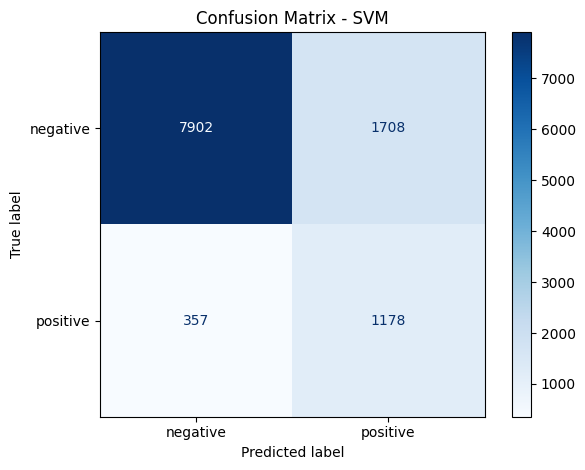

In [60]:
# Predict on test set
y_pred = model.predict(X_test_tfidf)

# Confusion matrix using encoded integer labels
cm = confusion_matrix(y_test_encoded, y_pred)

# Display with original class names
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix - SVM")
plt.grid(False)
plt.tight_layout()
plt.show()

# Multinomial Naive-Bayes


🔁 Fold 1/5
✅ Accuracy: 0.7921
              precision    recall  f1-score   support

    negative       0.78      0.82      0.80      2456
    positive       0.81      0.76      0.79      2456

    accuracy                           0.79      4912
   macro avg       0.79      0.79      0.79      4912
weighted avg       0.79      0.79      0.79      4912


🔁 Fold 2/5
✅ Accuracy: 0.7868
              precision    recall  f1-score   support

    negative       0.76      0.83      0.80      2456
    positive       0.81      0.74      0.78      2456

    accuracy                           0.79      4912
   macro avg       0.79      0.79      0.79      4912
weighted avg       0.79      0.79      0.79      4912


🔁 Fold 3/5
✅ Accuracy: 0.7795
              precision    recall  f1-score   support

    negative       0.75      0.83      0.79      2456
    positive       0.81      0.73      0.77      2456

    accuracy                           0.78      4912
   macro avg       0.78      0.78  

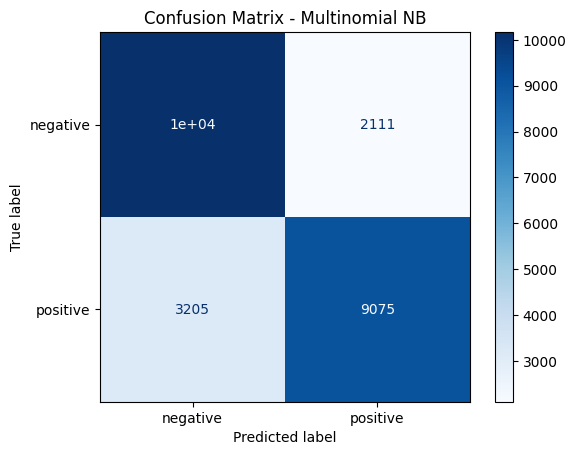

In [61]:
# Parameters
k = 5
skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)

all_true = []
all_pred = []
all_prob = []

accuracies = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X_all, y_train_bal)):
    print(f"\n🔁 Fold {fold + 1}/{k}")
    
    X_tr, X_val = X_all[train_idx], X_all[val_idx]
    y_tr, y_val = np.array(y_train_bal)[train_idx], np.array(y_train_bal)[val_idx]

    model = MultinomialNB()
    model.fit(X_tr, y_tr)

    y_pred = model.predict(X_val)
    y_proba = model.predict_proba(X_val)

    acc = accuracy_score(y_val, y_pred)
    accuracies.append(acc)
    print(f"✅ Accuracy: {acc:.4f}")
    print(classification_report(y_val, y_pred, target_names=label_encoder.classes_))

    all_true.extend(y_val)
    all_pred.extend(y_pred)
    all_prob.extend(y_proba)

# 🔷 Confusion Matrix
print("\n🧾 Confusion Matrix:")
cm = confusion_matrix(all_true, all_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix - Multinomial NB")
plt.show()


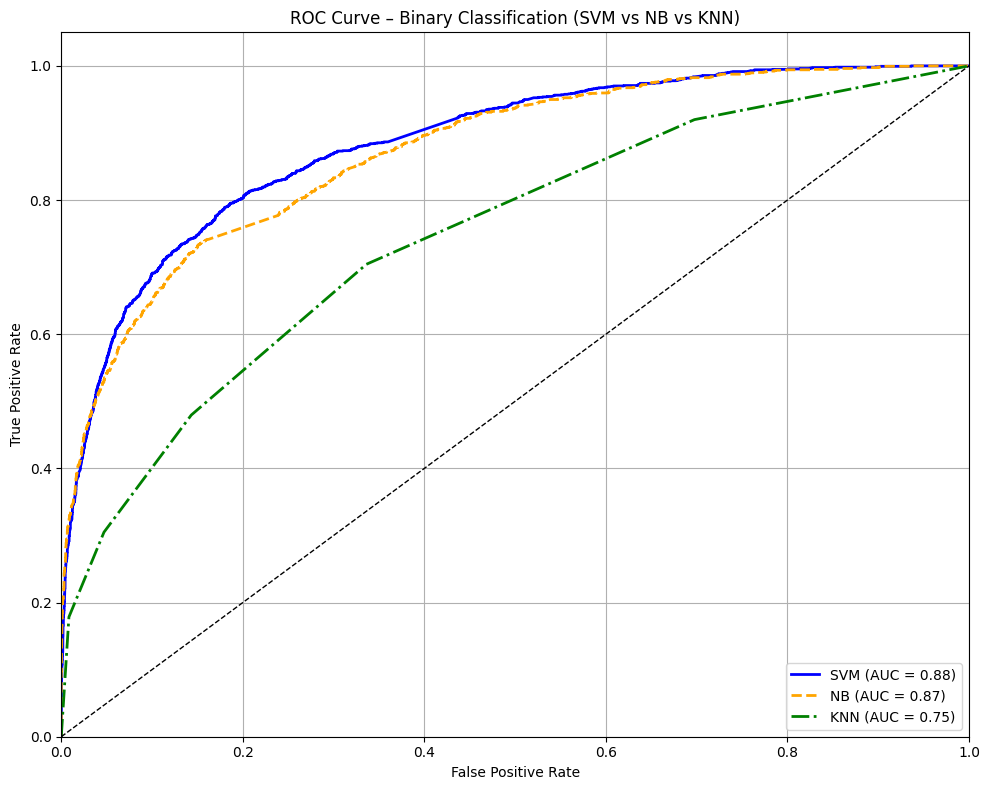

In [79]:
from sklearn.neighbors import KNeighborsClassifier

# 1. Make sure labels are binarized
n_classes = 2
y_test_bin = label_binarize(y_test_encoded, classes=[0, 1])

# 2. Calibrated Linear SVM
base_svc = LinearSVC(class_weight='balanced', max_iter=10000, dual='auto')
calibrated_svc = CalibratedClassifierCV(base_svc, method='sigmoid', cv=3)
calibrated_svc.fit(X_all, y_train_encoded)
y_score_svc = calibrated_svc.predict_proba(X_test_tfidf)[:, 1]

# 3. Multinomial NB
nb_model = MultinomialNB()
nb_model.fit(X_all, y_train_encoded)
y_score_nb = nb_model.predict_proba(X_test_tfidf)[:, 1]

# 4. K-Nearest Neighbors
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_all, y_train_encoded)
y_score_knn = knn_model.predict_proba(X_test_tfidf)[:, 1]

# 5. Compute ROC curves
fpr_svc, tpr_svc, _ = roc_curve(y_test_encoded, y_score_svc)
roc_auc_svc = auc(fpr_svc, tpr_svc)

fpr_nb, tpr_nb, _ = roc_curve(y_test_encoded, y_score_nb)
roc_auc_nb = auc(fpr_nb, tpr_nb)

fpr_knn, tpr_knn, _ = roc_curve(y_test_encoded, y_score_knn)
roc_auc_knn = auc(fpr_knn, tpr_knn)

# 6. Plot ROC curves
plt.figure(figsize=(10, 8))
plt.plot(fpr_svc, tpr_svc, color='blue', lw=2, label=f'SVM (AUC = {roc_auc_svc:.2f})')
plt.plot(fpr_nb, tpr_nb, color='orange', lw=2, linestyle='--', label=f'NB (AUC = {roc_auc_nb:.2f})')
plt.plot(fpr_knn, tpr_knn, color='green', lw=2, linestyle='-.', label=f'KNN (AUC = {roc_auc_knn:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve – Binary Classification (SVM vs NB vs KNN)')
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()


## Bengali Dataset Classes and Loaders

In [18]:
# Dataset Class
class BengaliDataset(Dataset):
    def __init__(self, padded_sequences, labels):
        self.sequences = torch.tensor(padded_sequences, dtype=torch.long)
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        return self.sequences[idx], self.labels[idx]

train_loader = DataLoader(BengaliDataset(X_train_pad, y_train_encoded), batch_size=64, shuffle=True)
val_loader = DataLoader(BengaliDataset(X_val_pad, y_val_encoded), batch_size=64)
test_loader = DataLoader(BengaliDataset(X_test_pad, y_test_encoded), batch_size=64)

In [19]:
# # 3. Load FastText Embeddings
# from gensim.models import KeyedVectors
# fasttext_model = KeyedVectors.load_word2vec_format("cc.bn.300.vec")

# fasttext_model.save("cc.bn.300_PN.kv")
# print("✅ FastText model saved in .kv format")

In [20]:
# Much faster than reloading .vec every time
from gensim.models import KeyedVectors
fasttext_model = KeyedVectors.load("cc.bn.300_PN.kv")

embedding_dim = 300
vocab_size = len(keras_tokenizer.word_index) + 1
embedding_matrix = np.zeros((vocab_size, embedding_dim))

for word, idx in keras_tokenizer.word_index.items():
    if word in fasttext_model:
        embedding_matrix[idx] = fasttext_model[word]
    else:
        embedding_matrix[idx] = np.random.normal(scale=0.6, size=(embedding_dim,))

print(embedding_matrix.shape)

(36959, 300)


# General Setup of CV(K-fold)

In [28]:
def run_kfold_cv(model_class, X, y, embedding_matrix=None, k=2, batch_size=64, epochs=5, model_save_dir="Bi-LSTM Models", test_loader=None):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)
    os.makedirs(model_save_dir, exist_ok=True)

    all_fold_acc = []

    best_fold_idx = -1
    best_fold_val_acc = 0.0
    best_fold_train_losses, best_fold_val_losses = [], []
    best_fold_train_accs, best_fold_val_accs = [], []

    for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
        print(f"\n🔁 Fold {fold + 1}/{k}")

        X_train, X_val = X[train_idx], X[val_idx]
        y_train, y_val = y[train_idx], y[val_idx]

        train_loader = DataLoader(BengaliDataset(X_train, y_train), batch_size=batch_size, shuffle=True)
        val_loader = DataLoader(BengaliDataset(X_val, y_val), batch_size=batch_size)

        model = model_class(embedding_matrix=embedding_matrix).to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
        criterion = nn.CrossEntropyLoss()

        train_losses, val_losses = [], []
        train_accuracies, val_accuracies = [], []

        best_acc = 0.0
        for epoch in range(epochs):
            model.train()
            total_loss, correct, total = 0, 0, 0
            for inputs, labels in train_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                optimizer.zero_grad()
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()
                total_loss += loss.item()
                preds = outputs.argmax(dim=1)
                correct += (preds == labels).sum().item()
                total += labels.size(0)

            avg_train_loss = total_loss / len(train_loader)
            train_acc = correct / total
            train_losses.append(avg_train_loss)
            train_accuracies.append(train_acc)

            # Validation
            model.eval()
            val_loss, correct, total = 0, 0, 0
            with torch.no_grad():
                for inputs, labels in val_loader:
                    inputs, labels = inputs.to(device), labels.to(device)
                    outputs = model(inputs)
                    val_loss += criterion(outputs, labels).item()
                    preds = outputs.argmax(dim=1)
                    correct += (preds == labels).sum().item()
                    total += labels.size(0)

            avg_val_loss = val_loss / len(val_loader)
            val_acc = correct / total
            val_losses.append(avg_val_loss)
            val_accuracies.append(val_acc)

            print(f"Epoch {epoch+1}/{epochs} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f}")

            if val_acc > best_acc:
                best_acc = val_acc
                best_path = os.path.join(model_save_dir, f"best_fold_{fold+1}.pth")
                torch.save(model.state_dict(), best_path)
                print(f"✅ Best model for fold {fold+1} saved to {best_path}")

        all_fold_acc.append(best_acc)

        # Track best fold info
        if best_acc > best_fold_val_acc:
            best_fold_val_acc = best_acc
            best_fold_idx = fold + 1
            best_fold_train_losses = train_losses
            best_fold_val_losses = val_losses
            best_fold_train_accs = train_accuracies
            best_fold_val_accs = val_accuracies

        print(classification_report(y_val, model(torch.tensor(X_val).to(device)).argmax(dim=1).cpu().numpy(), target_names=label_encoder.classes_))

    print(f"\n📊 Average K-Fold Accuracy: {np.mean(all_fold_acc):.4f}")
    print(f"🏆 Best Fold: {best_fold_idx} | Best Accuracy: {best_fold_val_acc:.4f}")

    # 📉 Plot Loss - Best Fold
    plt.figure(figsize=(10, 6))
    plt.plot(best_fold_train_losses, label="Train Loss", linestyle='-')
    plt.plot(best_fold_val_losses, label="Validation Loss", linestyle='--')
    plt.title(f"Bi-LSTM Model: Training and Validation Loss (Best Fold {best_fold_idx})")
    plt.xlabel("Number of epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # 📈 Plot Accuracy - Best Fold
    plt.figure(figsize=(10, 6))
    plt.plot(best_fold_train_accs, label="Train Accuracy", linestyle='-')
    plt.plot(best_fold_val_accs, label="Validation Accuracy", linestyle='--')
    plt.title(f"Bi-LSTM Model: Training and Validation Accuracy (Best Fold {best_fold_idx})")
    plt.xlabel("Number of epochs")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


In [29]:
def evaluate_all_folds_on_test(
    model_class,
    label_encoder,
    model_dir,
    input_type="standard",     # or "bert"
    embedding_matrix=None,
    device=None,
    max_folds=20,
    batch_size=32,
    X_test=None,
    y_test=None,
    tokenizer=None,
    test_loader=None,
    max_len=100
):
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Build test_loader if not provided
    if test_loader is None:
        assert X_test is not None and y_test is not None, "X_test and y_test must be provided if test_loader is not."
        
        if input_type == "bert":
            assert tokenizer is not None, "Tokenizer must be provided for BERT input."
            test_dataset = BERTDataset(X_test, y_test, tokenizer, max_len=max_len)
        else:
            test_dataset = BengaliDataset(X_test, y_test)

        test_loader = DataLoader(test_dataset, batch_size=batch_size)

    best_model = None
    best_acc = 0.0
    best_model_path = None

    # ✅ Always pass embedding_matrix (even if None)
    for fold_num in range(1, max_folds + 1):
        model_path = os.path.join(model_dir, f"best_fold_{fold_num}.pth")
        if not os.path.exists(model_path):
            continue

        print(f"\n📦 Loading best model from fold {fold_num}: {model_path}")
        model = model_class(embedding_matrix=embedding_matrix).to(device)

        model.load_state_dict(torch.load(model_path))
        model.eval()

        all_preds, all_labels = [], []
        with torch.no_grad():
            for batch in test_loader:
                if input_type == "bert":
                    input_ids = batch['input_ids'].to(device)
                    attention_mask = batch['attention_mask'].to(device)
                    labels = batch['labels'].to(device)
                    outputs = model(input_ids, attention_mask)
                else:
                    inputs, labels = batch
                    inputs, labels = inputs.to(device), labels.to(device)
                    outputs = model(inputs)

                preds = torch.argmax(outputs, dim=1)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())

        acc = accuracy_score(all_labels, all_preds)
        print(f"🧪 Fold {fold_num} Test Accuracy: {acc:.4f}")
        print(classification_report(all_labels, all_preds, target_names=label_encoder.classes_))

        if acc > best_acc:
            best_acc = acc
            best_model = model
            best_model_path = model_path

    if best_model:
        print(f"\n🏆 Best model loaded from: {best_model_path}")
        print(f"✅ Highest Test Accuracy: {best_acc:.4f}")
        return best_model, best_model_path, best_acc
    else:
        print("⚠️ No valid fold models found.")
        return None, None, None


# Bi-LSTM model

In [30]:
# 5. BiLSTM Model with Pretrained Embedding
class BiLSTMClassifier(nn.Module):
    def __init__(self, embedding_matrix, hidden_dim=128, output_dim=2, freeze=False):
        super(BiLSTMClassifier, self).__init__()
        num_embeddings, embedding_dim = embedding_matrix.shape
        self.embedding = nn.Embedding.from_pretrained(
            torch.tensor(embedding_matrix, dtype=torch.float32),
            freeze=freeze,
            padding_idx=0
        )
        self.bilstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True, bidirectional=True, num_layers=2)
        self.dropout = nn.Dropout(0.5)
        self.fc1 = nn.Linear(hidden_dim * 2, 64)
        self.fc2 = nn.Linear(64, output_dim)

    def forward(self, x):
        x = self.embedding(x)
        _, (hidden, _) = self.bilstm(x)
        hidden_cat = torch.cat((hidden[-2], hidden[-1]), dim=1)
        x = self.dropout(hidden_cat)
        x = F.relu(self.fc1(x))
        return self.fc2(x)


🔁 Fold 1/2
Epoch 1/5 | Train Loss: 0.3246 | Val Loss: 0.2334 | Train Acc: 0.8571 | Val Acc: 0.9055
✅ Best model for fold 1 saved to Bi_LSTM_Models\best_fold_1.pth
Epoch 2/5 | Train Loss: 0.1256 | Val Loss: 0.2765 | Train Acc: 0.9544 | Val Acc: 0.9072
✅ Best model for fold 1 saved to Bi_LSTM_Models\best_fold_1.pth
Epoch 3/5 | Train Loss: 0.0541 | Val Loss: 0.3023 | Train Acc: 0.9837 | Val Acc: 0.9033
Epoch 4/5 | Train Loss: 0.0257 | Val Loss: 0.3454 | Train Acc: 0.9923 | Val Acc: 0.9009
Epoch 5/5 | Train Loss: 0.0171 | Val Loss: 0.4597 | Train Acc: 0.9950 | Val Acc: 0.8989
              precision    recall  f1-score   support

    negative       0.89      0.92      0.90      6140
    positive       0.91      0.88      0.90      6140

    accuracy                           0.90     12280
   macro avg       0.90      0.90      0.90     12280
weighted avg       0.90      0.90      0.90     12280


🔁 Fold 2/2
Epoch 1/5 | Train Loss: 0.3368 | Val Loss: 0.2520 | Train Acc: 0.8544 | Val Acc: 

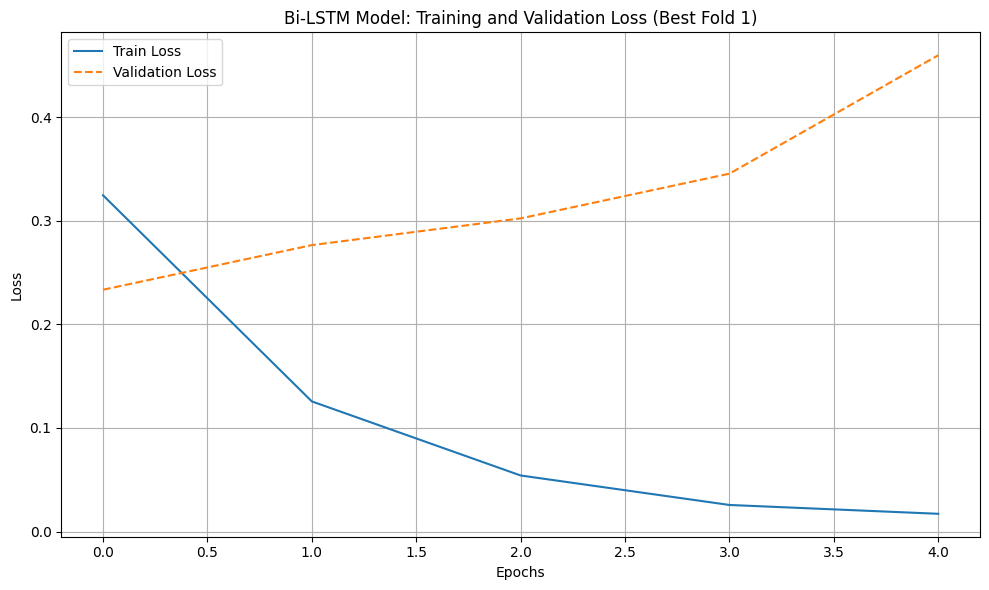

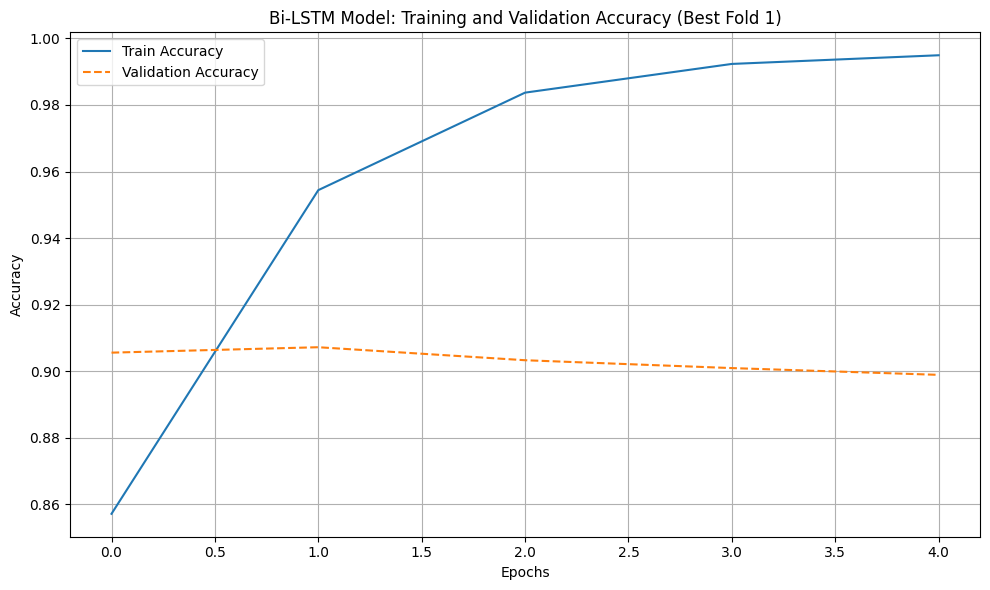

In [33]:
run_kfold_cv(
    model_class=lambda embedding_matrix: BiLSTMClassifier(
        embedding_matrix=embedding_matrix,
        hidden_dim=256,
        output_dim=2,   # or 3 for multi-class
        freeze=False
    ),
    X=X_np,
    y=y_np,
    embedding_matrix=embedding_matrix,
    k=2,
    batch_size=16,
    epochs=5,
    model_save_dir="Bi_LSTM_Models",
    test_loader=test_loader
)

In [32]:
best_model, best_model_path, best_acc = evaluate_all_folds_on_test(
    model_class=lambda embedding_matrix: BiLSTMClassifier(
        embedding_matrix=embedding_matrix,
        hidden_dim=256,
        output_dim=2,
        freeze=False
    ),
    label_encoder=label_encoder,
    model_dir="Bi_LSTM_Models",
    embedding_matrix=embedding_matrix,
    input_type="standard",
    X_test=X_test_pad,
    y_test=y_test_encoded
)


📦 Loading best model from fold 1: Bi_LSTM_Models\best_fold_1.pth
🧪 Fold 1 Test Accuracy: 0.9141
              precision    recall  f1-score   support

    negative       0.98      0.92      0.95      9610
    positive       0.63      0.89      0.74      1535

    accuracy                           0.91     11145
   macro avg       0.81      0.90      0.84     11145
weighted avg       0.93      0.91      0.92     11145


📦 Loading best model from fold 2: Bi_LSTM_Models\best_fold_2.pth
🧪 Fold 2 Test Accuracy: 0.9045
              precision    recall  f1-score   support

    negative       0.98      0.91      0.94      9610
    positive       0.61      0.86      0.71      1535

    accuracy                           0.90     11145
   macro avg       0.79      0.89      0.83     11145
weighted avg       0.93      0.90      0.91     11145


📦 Loading best model from fold 3: Bi_LSTM_Models\best_fold_3.pth
🧪 Fold 3 Test Accuracy: 0.9164
              precision    recall  f1-score   support



In [27]:
# Load best model from the folder
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
best_model.load_state_dict(torch.load("Bi_LSTM_Models/best_fold_3.pth"))
best_model.to(device)
best_model.eval()

BiLSTMClassifier(
  (embedding): Embedding(36959, 300, padding_idx=0)
  (bilstm): LSTM(300, 256, num_layers=2, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc1): Linear(in_features=512, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=2, bias=True)
)

In [31]:
# # 6. Train & Evaluate Model
# import os
# model = BiLSTMClassifier(embedding_matrix, hidden_dim=256, output_dim=2, freeze=False)
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# model.to(device)

# criterion = nn.CrossEntropyLoss()
# optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
# epochs = 30
# best_acc = 0.0

# os.makedirs("Bi-LSTM Models", exist_ok=True)

# for epoch in range(epochs):
#     model.train()
#     total_loss = 0
#     for inputs, labels in train_loader:
#         inputs, labels = inputs.to(device), labels.to(device)
#         optimizer.zero_grad()
#         outputs = model(inputs)
#         loss = criterion(outputs, labels)
#         loss.backward()
#         optimizer.step()
#         total_loss += loss.item()

#     print(f"Epoch {epoch+1} | Train Loss: {total_loss/len(train_loader):.4f}")

#     model.eval()
#     all_preds, all_labels = [], []
#     with torch.no_grad():
#         for inputs, labels in val_loader:
#             inputs, labels = inputs.to(device), labels.to(device)
#             outputs = model(inputs)
#             preds = torch.argmax(outputs, dim=1)
#             all_preds.extend(preds.cpu().numpy())
#             all_labels.extend(labels.cpu().numpy())

#     acc = accuracy_score(all_labels, all_preds)
#     print(f"Validation Accuracy: {acc:.4f}")
#     print(classification_report(all_labels, all_preds, target_names=label_encoder.classes_))

#     if acc > best_acc:
#         best_acc = acc
#         torch.save(model.state_dict(), "Bi-LSTM Models/best_bilstm_model.pth")
#         print("✅ Best model saved")


In [32]:
# #7. Test set evaluation
# model.eval()
# test_preds, test_labels = [], []
# with torch.no_grad():
#     for inputs, labels in test_loader:
#         inputs, labels = inputs.to(device), labels.to(device)
#         outputs = model(inputs)
#         preds = torch.argmax(outputs, dim=1)
#         test_preds.extend(preds.cpu().numpy())
#         test_labels.extend(labels.cpu().numpy())

# print("🔍 Test Set Evaluation:")
# print(classification_report(test_labels, test_preds, target_names=label_encoder.classes_))


# CNN Text Classification with PyTorch – Full Pipeline

In [31]:
#2. CNN Model for Text Classification
class CNNTextClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, output_dim=2, kernel_sizes=[3,4,5], num_filters=100, dropout=0.5):
        super(CNNTextClassifier, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)

        self.convs = nn.ModuleList([
            nn.Conv2d(1, num_filters, (k, embedding_dim)) for k in kernel_sizes
        ])

        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(num_filters * len(kernel_sizes), output_dim)

    def forward(self, x):
        embedded = self.embedding(x)              # (batch_size, seq_len, embed_dim)
        embedded = embedded.unsqueeze(1)          # (batch_size, 1, seq_len, embed_dim)

        conved = [F.relu(conv(embedded)).squeeze(3) for conv in self.convs]  # [(batch_size, num_filters, ~), ...]

        pooled = [F.max_pool1d(c, c.shape[2]).squeeze(2) for c in conved]   # [(batch_size, num_filters), ...]

        cat = torch.cat(pooled, dim=1)            # (batch_size, num_filters * len(kernel_sizes))
        return self.fc(self.dropout(cat))

In [ ]:
run_kfold_cv(
    model_class=lambda embedding_matrix: CNNTextClassifier(
        vocab_size=len(keras_tokenizer.word_index) + 1,
        embedding_dim=300,
        output_dim=2
    ),
    X=X_train_pad,
    y=y_train_encoded,
    embedding_matrix=None,  # Will be passed, but ignored
    k=5,
    batch_size=64,
    epochs=50,
    model_save_dir="CNN_Models",
    test_loader=test_loader
)



🔁 Fold 1/5
Epoch 1 | Train Loss: 0.3675
Epoch 2 | Train Loss: 0.1842
Epoch 3 | Train Loss: 0.1098
Epoch 4 | Train Loss: 0.0708
Epoch 5 | Train Loss: 0.0547
Epoch 6 | Train Loss: 0.0379
Epoch 7 | Train Loss: 0.0333
Epoch 8 | Train Loss: 0.0271
Epoch 9 | Train Loss: 0.0235
Epoch 10 | Train Loss: 0.0221
Epoch 11 | Train Loss: 0.0244


In [ ]:
best_model, best_model_path, best_acc = evaluate_all_folds_on_test(
    model_class=lambda embedding_matrix: CNNTextClassifier(
        vocab_size=len(keras_tokenizer.word_index) + 1,
        embedding_dim=300,
        output_dim=2
    ),                      # same lambda
    label_encoder=label_encoder,
    model_dir="CNN_Models",
    input_type="standard",
    embedding_matrix=None,
    X_test=X_test_pad,
    y_test=y_test_encoded
)


In [46]:
# Load best CNN model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
best_model.load_state_dict(torch.load("CNN_Models/best_fold_1.pth"))
best_model.to(device)
best_model.eval()


CNNTextClassifier(
  (embedding): Embedding(38575, 300, padding_idx=0)
  (convs): ModuleList(
    (0): Conv2d(1, 100, kernel_size=(3, 300), stride=(1, 1))
    (1): Conv2d(1, 100, kernel_size=(4, 300), stride=(1, 1))
    (2): Conv2d(1, 100, kernel_size=(5, 300), stride=(1, 1))
  )
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=300, out_features=2, bias=True)
)

In [47]:
# #4. Training & Validation Loop
# import os
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# vocab_size = len(keras_tokenizer.word_index) + 1
# model = CNNTextClassifier(vocab_size=vocab_size).to(device)

# criterion = nn.CrossEntropyLoss()
# optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
# epochs = 30
# best_acc = 0.0
# os.makedirs("CNN Models", exist_ok=True)

# for epoch in range(epochs):
#     model.train()
#     total_loss = 0
#     for inputs, labels in train_loader:
#         inputs, labels = inputs.to(device), labels.to(device)
#         optimizer.zero_grad()
#         outputs = model(inputs)
#         loss = criterion(outputs, labels)
#         loss.backward()
#         optimizer.step()
#         total_loss += loss.item()

#     print(f"Epoch {epoch+1} | Train Loss: {total_loss/len(train_loader):.4f}")

#     # Validation
#     model.eval()
#     val_preds, val_labels = [], []
#     with torch.no_grad():
#         for inputs, labels in val_loader:
#             inputs, labels = inputs.to(device), labels.to(device)
#             outputs = model(inputs)
#             preds = torch.argmax(outputs, dim=1)
#             val_preds.extend(preds.cpu().numpy())
#             val_labels.extend(labels.cpu().numpy())

#     acc = accuracy_score(val_labels, val_preds)
#     print(f"Validation Accuracy: {acc:.4f}")
#     print(classification_report(val_labels, val_preds, target_names=label_encoder.classes_))

#     if acc > best_acc:
#         best_acc = acc
#         save_path = os.path.join("CNN Models", "best_cnn_model.pth")
#         torch.save(model.state_dict(), save_path)
#         print("✅ Best CNN model saved!")


# Pipeline for CNN + Bi-LSTM Hybrid (PyTorch)

In [ ]:
#1. Model Definition
class CNN_BiLSTM_Hybrid(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=128, output_dim=2, dropout=0.5, embedding_weights=None):
        super(CNN_BiLSTM_Hybrid, self).__init__()

        if embedding_weights is not None:
            self.embedding = nn.Embedding.from_pretrained(
                torch.tensor(embedding_weights, dtype=torch.float32),
                freeze=True,
                padding_idx=0
            )
        else:
            self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)

        self.conv1 = nn.Conv1d(in_channels=embedding_dim, out_channels=128, kernel_size=5)
        self.pool = nn.MaxPool1d(kernel_size=2)

        self.bilstm = nn.LSTM(input_size=128, hidden_size=hidden_dim, batch_first=True, bidirectional=True)

        self.dropout = nn.Dropout(dropout)
        self.fc1 = nn.Linear(hidden_dim * 2, 64)
        self.fc2 = nn.Linear(64, output_dim)

    def forward(self, x):
        x = self.embedding(x)                      # (batch_size, seq_len, embedding_dim)
        x = x.permute(0, 2, 1)                     # (batch_size, embedding_dim, seq_len) for Conv1D
        x = F.relu(self.conv1(x))                 # (batch_size, out_channels, new_seq_len)
        x = self.pool(x)                          # (batch_size, out_channels, pooled_len)
        x = x.permute(0, 2, 1)                    # (batch_size, pooled_len, out_channels)
        _, (hidden, _) = self.bilstm(x)           # hidden: (2, batch, hidden_dim)
        hidden = torch.cat((hidden[-2], hidden[-1]), dim=1)  # (batch_size, hidden_dim*2)
        x = self.dropout(hidden)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

In [ ]:
run_kfold_cv(
    model_class=lambda embedding_matrix: CNN_BiLSTM_Hybrid(
        vocab_size=embedding_matrix.shape[0],
        embedding_dim=embedding_matrix.shape[1],
        hidden_dim=256,
        output_dim=2,
        embedding_weights=embedding_matrix
    ),
    X=X_train_pad,
    y=y_train_encoded,
    embedding_matrix=embedding_matrix,
    k=5,
    batch_size=64,
    epochs=50,
    model_save_dir="CNN_BiLSTM_Models",
    test_loader=test_loader
)


In [ ]:
best_model, best_model_path, best_acc = evaluate_all_folds_on_test(
    model_class=lambda embedding_matrix: CNN_BiLSTM_Hybrid(
        vocab_size=embedding_matrix.shape[0],
        embedding_dim=embedding_matrix.shape[1],
        hidden_dim=256,
        output_dim=2,
        embedding_weights=embedding_matrix
    ),
    label_encoder=label_encoder,
    model_dir="CNN_BiLSTM_Models",
    input_type="standard",
    embedding_matrix=embedding_matrix,
    X_test=X_test_pad,
    y_test=y_test_encoded
)


In [48]:
# #5. Training + Validation Loop
# import os
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# vocab_size = len(keras_tokenizer.word_index) + 1
# model = CNN_BiLSTM_Hybrid(vocab_size).to(device)

# criterion = nn.CrossEntropyLoss()
# optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
# epochs = 30
# best_acc = 0.0
# os.makedirs("CNN_BiLSTM_Models", exist_ok=True)

# for epoch in range(epochs):
#     model.train()
#     total_loss = 0
#     for inputs, labels in train_loader:
#         inputs, labels = inputs.to(device), labels.to(device)
#         optimizer.zero_grad()
#         outputs = model(inputs)
#         loss = criterion(outputs, labels)
#         loss.backward()
#         optimizer.step()
#         total_loss += loss.item()

#     print(f"Epoch {epoch+1} | Train Loss: {total_loss/len(train_loader):.4f}")

#     # Validation
#     model.eval()
#     val_preds, val_labels = [], []
#     with torch.no_grad():
#         for inputs, labels in val_loader:
#             inputs, labels = inputs.to(device), labels.to(device)
#             outputs = model(inputs)
#             preds = torch.argmax(outputs, dim=1)
#             val_preds.extend(preds.cpu().numpy())
#             val_labels.extend(labels.cpu().numpy())

#     acc = accuracy_score(val_labels, val_preds)
#     print(f"Validation Accuracy: {acc:.4f}")
#     print(classification_report(val_labels, val_preds, target_names=label_encoder.classes_))

#     if acc > best_acc:
#         best_acc = acc
#         save_path = os.path.join("CNN_BiLSTM_Models", "best_cnn_bilstm_model.pth")
#         torch.save(model.state_dict(), save_path)
#         print("✅ Best hybrid model saved.")

In [53]:
# Load best CNN BiLSTM model
best_model.load_state_dict(torch.load("CNN_BiLSTM_Models/best_fold_1.pth"))
best_model.to(device)
best_model.eval()


CNN_BiLSTM_Hybrid(
  (embedding): Embedding(38575, 300, padding_idx=0)
  (conv1): Conv1d(300, 128, kernel_size=(5,), stride=(1,))
  (pool): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (bilstm): LSTM(128, 256, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc1): Linear(in_features=512, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=2, bias=True)
)

# Bi-LSTM + Attention Model in Keras

In [28]:
#1. Model Definition (Bi-LSTM + Attention)
class BiLSTM_Attention(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=128, output_dim=2, dropout=0.5, embedding_weights=None):
        super(BiLSTM_Attention, self).__init__()

        if embedding_weights is not None:
            self.embedding = nn.Embedding.from_pretrained(
                torch.tensor(embedding_weights, dtype=torch.float32),
                freeze=True,
                padding_idx=0
            )
        else:
            self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)

        self.bilstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.attention = nn.Linear(hidden_dim * 2, 1)
        self.dropout = nn.Dropout(dropout)
        self.fc1 = nn.Linear(hidden_dim * 2, 64)
        self.fc2 = nn.Linear(64, output_dim)

    def forward(self, x):
        embedded = self.embedding(x)                       # (batch_size, seq_len, embedding_dim)
        lstm_out, _ = self.bilstm(embedded)                # (batch_size, seq_len, hidden_dim*2)

        # Attention weights
        attn_weights = torch.tanh(self.attention(lstm_out))  # (batch_size, seq_len, 1)
        attn_weights = torch.softmax(attn_weights, dim=1)    # normalize across seq_len

        # Context vector
        context = torch.sum(attn_weights * lstm_out, dim=1)  # (batch_size, hidden_dim*2)

        x = self.dropout(context)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

In [ ]:
run_kfold_cv(
    model_class=lambda embedding_matrix: BiLSTM_Attention(
        vocab_size=len(keras_tokenizer.word_index) + 1,
        embedding_dim=300,
        hidden_dim=256,
        output_dim=2,
        embedding_weights=embedding_matrix
    ),
    X=X_train_pad,
    y=y_train_encoded,
    embedding_matrix=embedding_matrix,
    k=5,
    batch_size=64,
    epochs=50,
    model_save_dir="BiLSTM_Attention_Models",
    test_loader=test_loader
)



🔁 Fold 1/5
Epoch 1 | Train Loss: 0.5892
Epoch 2 | Train Loss: 0.4510
Epoch 3 | Train Loss: 0.3680
Epoch 4 | Train Loss: 0.2994
Epoch 5 | Train Loss: 0.2454
Epoch 6 | Train Loss: 0.2086
Epoch 7 | Train Loss: 0.1831
Epoch 8 | Train Loss: 0.1564
Epoch 9 | Train Loss: 0.1392
Epoch 10 | Train Loss: 0.1240
Epoch 11 | Train Loss: 0.1141
Epoch 12 | Train Loss: 0.1001
Epoch 13 | Train Loss: 0.0896
Epoch 14 | Train Loss: 0.0832
Epoch 15 | Train Loss: 0.0737
Epoch 16 | Train Loss: 0.0647
Epoch 17 | Train Loss: 0.0592
Epoch 18 | Train Loss: 0.0524
Epoch 19 | Train Loss: 0.0503
Epoch 20 | Train Loss: 0.0446
Epoch 21 | Train Loss: 0.0433
Epoch 22 | Train Loss: 0.0410
Epoch 23 | Train Loss: 0.0385
Epoch 24 | Train Loss: 0.0335
Epoch 25 | Train Loss: 0.0304
Epoch 26 | Train Loss: 0.0289
Epoch 27 | Train Loss: 0.0263
Epoch 28 | Train Loss: 0.0261
Epoch 29 | Train Loss: 0.0238
Epoch 30 | Train Loss: 0.6150
Epoch 31 | Train Loss: 0.4580
Epoch 32 | Train Loss: 0.2090
Epoch 33 | Train Loss: 0.0882
Epoch 3

In [ ]:
best_model, best_model_path, best_acc = evaluate_all_folds_on_test(
    model_class=lambda embedding_matrix: BiLSTM_Attention(
        vocab_size=len(keras_tokenizer.word_index) + 1,
        embedding_dim=300,
        hidden_dim=256,
        output_dim=2,
        embedding_weights=embedding_matrix
    ),
    label_encoder=label_encoder,
    model_dir="BiLSTM_Attention_Models",
    input_type="standard",
    embedding_matrix=embedding_matrix,
    X_test=X_test_pad,
    y_test=y_test_encoded
)

In [ ]:
# Load best BiLSTM Attention model
best_model.load_state_dict(torch.load("BiLSTM_Attention_Models/best_fold_1.pth"))
best_model.to(device)
best_model.eval()


In [53]:
# #5. Training + Validation Loop
# import os
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# vocab_size = len(keras_tokenizer.word_index) + 1
# model = BiLSTM_Attention(vocab_size).to(device)

# criterion = nn.CrossEntropyLoss()
# optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
# epochs = 30
# best_acc = 0.0
# os.makedirs("BiLSTM_Attention_Models", exist_ok=True)

# for epoch in range(epochs):
#     model.train()
#     total_loss = 0
#     for inputs, labels in train_loader:
#         inputs, labels = inputs.to(device), labels.to(device)
#         optimizer.zero_grad()
#         outputs = model(inputs)
#         loss = criterion(outputs, labels)
#         loss.backward()
#         optimizer.step()
#         total_loss += loss.item()

#     print(f"Epoch {epoch+1} | Train Loss: {total_loss/len(train_loader):.4f}")

#     # Validation
#     model.eval()
#     val_preds, val_labels = [], []
#     with torch.no_grad():
#         for inputs, labels in val_loader:
#             inputs, labels = inputs.to(device), labels.to(device)
#             outputs = model(inputs)
#             preds = torch.argmax(outputs, dim=1)
#             val_preds.extend(preds.cpu().numpy())
#             val_labels.extend(labels.cpu().numpy())

#     acc = accuracy_score(val_labels, val_preds)
#     print(f"Validation Accuracy: {acc:.4f}")
#     print(classification_report(val_labels, val_preds, target_names=label_encoder.classes_))

#     if acc > best_acc:
#         best_acc = acc
#         torch.save(model.state_dict(), os.path.join("BiLSTM_Attention_Models", "best_bilstm_attention_model.pth"))
#         print("✅ Best attention model saved.")

# An BERT + CNN + Bi-LSTM Hybrid Model (PyTorch)

In [ ]:
# from transformers import BertModel, BertTokenizerFast
# print("🔤 First 5 texts:")
# for i, text in enumerate(X_train_bal_clean[:5]):
#     print(f"{i+1}. {text}")

# # Show the first 5 encoded labels
# print("\n🏷 First 5 encoded labels:")
# print(y_train_encoded[:5])

In [ ]:
def run_kfold_bert_cnn_lstm(X, y, k=2, num_classes=2, epochs=3, batch_size=16, max_len=100):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)
    tokenizer = AutoTokenizer.from_pretrained('bert-base-multilingual-cased')
    os.makedirs("BERT_CNN_LSTM_Models", exist_ok=True)

    for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
        print(f"\n🧪 Fold {fold+1}/{k}")

        X_train = [X[i] for i in train_idx]
        y_train = [y[i] for i in train_idx]
        X_val = [X[i] for i in val_idx]
        y_val = [y[i] for i in val_idx]

        train_dataset = BERTDataset(X_train, y_train, tokenizer, max_len=max_len)
        val_dataset = BERTDataset(X_val, y_val, tokenizer, max_len=max_len)

        train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
        val_loader = DataLoader(val_dataset, batch_size=batch_size)

        model = BERT_CNN_LSTM(output_dim=num_classes).to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=2e-5)
        criterion = torch.nn.CrossEntropyLoss()

        best_acc = 0.0
        for epoch in range(epochs):
            model.train()
            total_loss = 0
            for batch in train_loader:
                input_ids = batch['input_ids'].to(device)
                attention_mask = batch['attention_mask'].to(device)
                labels = batch['labels'].to(device)

                optimizer.zero_grad()
                outputs = model(input_ids, attention_mask)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()
                total_loss += loss.item()

            print(f"Epoch {epoch+1} | Train Loss: {total_loss / len(train_loader):.4f}")

            # Validation
            model.eval()
            all_preds, all_labels = [], []
            with torch.no_grad():
                for batch in val_loader:
                    input_ids = batch['input_ids'].to(device)
                    attention_mask = batch['attention_mask'].to(device)
                    labels = batch['labels'].to(device)

                    outputs = model(input_ids, attention_mask)
                    preds = torch.argmax(outputs, dim=1)

                    all_preds.extend(preds.cpu().numpy())
                    all_labels.extend(labels.cpu().numpy())

            acc = accuracy_score(all_labels, all_preds)
            print(f"Validation Accuracy: {acc:.4f}")
            print(classification_report(all_labels, all_preds))

            # Save best model for this fold
            if acc > best_acc:
                best_acc = acc
                model_path = f"BERT_CNN_LSTM_Models/best_fold_{fold+1}.pth"
                torch.save(model.state_dict(), model_path)
                print(f"✅ Saved best model for fold {fold+1} to {model_path}")


In [ ]:
class BERT_CNN_LSTM(nn.Module):
    def __init__(self, bert_model_name='bert-base-multilingual-cased', hidden_dim=128, output_dim=2, dropout=0.5):
        super(BERT_CNN_LSTM, self).__init__()
        
        self.bert = AutoModel.from_pretrained(bert_model_name)
        for param in self.bert.parameters():
            param.requires_grad = False  # freeze BERT safely

        self.conv1 = nn.Conv1d(in_channels=self.bert.config.hidden_size, out_channels=128, kernel_size=3, padding=1)
        self.lstm = nn.LSTM(input_size=128, hidden_size=hidden_dim, batch_first=True, bidirectional=True)
        
        self.dropout = nn.Dropout(dropout)
        self.fc1 = nn.Linear(hidden_dim * 2, 64)
        self.fc2 = nn.Linear(64, output_dim)

    def forward(self, input_ids, attention_mask):
        bert_outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        last_hidden_state = bert_outputs.last_hidden_state
        
        x = last_hidden_state.permute(0, 2, 1)
        x = F.relu(self.conv1(x))
        x = x.permute(0, 2, 1)
        lstm_out, _ = self.lstm(x)
        pooled = torch.mean(lstm_out, dim=1)
        
        x = self.dropout(pooled)
        x = F.relu(self.fc1(x))
        return self.fc2(x)


In [ ]:
class BERTDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=100):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer.encode_plus(
            str(self.texts[idx]),
            add_special_tokens=True,
            max_length=self.max_len,
            truncation=True,
            padding='max_length',
            return_attention_mask=True,
            return_tensors='pt'
        )
        return {
            'input_ids': encoding['input_ids'].squeeze(0),
            'attention_mask': encoding['attention_mask'].squeeze(0),
            'labels': torch.tensor(self.labels[idx], dtype=torch.long)
        }


In [ ]:
run_kfold_bert_cnn_lstm(X_train_bal_clean, y_train_encoded, k=3, num_classes=2, epochs=30, batch_size=16)

In [ ]:
best_model, best_model_path, best_acc = evaluate_all_folds_on_test(
    model_class=lambda embedding_matrix=None: BERT_CNN_LSTM(output_dim=2),
    label_encoder=label_encoder,
    model_dir="BERT_CNN_LSTM_Models",
    input_type="bert",
    X_test=X_test_clean,
    y_test=y_test_encoded,
    tokenizer=AutoTokenizer.from_pretrained("bert-base-multilingual-cased"),
    max_len=100
)

In [ ]:
best_model.load_state_dict(torch.load("BERT_CNN_LSTM_Models/best_fold_1.pth"))
best_model.to(device)
best_model.eval()


In [ ]:
# #3. Prepare Dataloaders

# tokenizer = AutoTokenizer.from_pretrained('bert-base-multilingual-cased')

# train_dataset = BERTDataset(X_train_bal_clean, y_train_encoded, tokenizer)
# val_dataset   = BERTDataset(X_val_clean, y_val_encoded, tokenizer)
# test_dataset  = BERTDataset(X_test_clean, y_test_encoded, tokenizer)

# train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
# val_loader   = DataLoader(val_dataset, batch_size=16)
# test_loader  = DataLoader(test_dataset, batch_size=16)


In [24]:
# def train(model, loader, optimizer, criterion):
#     model.train()
#     total_loss = 0
#     for batch in loader:
#         optimizer.zero_grad()
#         input_ids = batch["input_ids"].to(device)
#         attention_mask = batch["attention_mask"].to(device)
#         labels = batch["label"].to(device)

#         outputs = model(input_ids, attention_mask)
#         loss = criterion(outputs, labels)
#         loss.backward()
#         optimizer.step()
#         total_loss += loss.item()
#     return total_loss / len(loader)

# def evaluate(model, loader):
#     model.eval()
#     all_preds, all_labels = [], []
#     with torch.no_grad():
#         for batch in loader:
#             input_ids = batch["input_ids"].to(device)
#             attention_mask = batch["attention_mask"].to(device)
#             labels = batch["label"].to(device)

#             outputs = model(input_ids, attention_mask)
#             preds = torch.argmax(outputs, dim=1)
#             all_preds.extend(preds.cpu().numpy())
#             all_labels.extend(labels.cpu().numpy())
#     acc = accuracy_score(all_labels, all_preds)
#     return acc, classification_report(all_labels, all_preds, digits=4)


In [ ]:
# #5. Training + Validation Loop
# import os
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# model = BERT_CNN_LSTM().to(device)

# criterion = nn.CrossEntropyLoss()
# optimizer = torch.optim.Adam(model.parameters(), lr=2e-5)
# epochs = 30
# best_acc = 0.0
# os.makedirs("BERT_CNN_LSTM_Models", exist_ok=True)

# for epoch in range(epochs):
#     model.train()
#     total_loss = 0
#     for batch in train_loader:
#         input_ids = batch['input_ids'].to(device)
#         attention_mask = batch['attention_mask'].to(device)
#         labels = batch['labels'].to(device)

#         optimizer.zero_grad()
#         outputs = model(input_ids, attention_mask)
#         loss = criterion(outputs, labels)
#         loss.backward()
#         optimizer.step()
#         total_loss += loss.item()
    
#     print(f"Epoch {epoch+1} | Train Loss: {total_loss/len(train_loader):.4f}")

#     # Validation
#     model.eval()
#     all_preds, all_labels = [], []
#     with torch.no_grad():
#         for batch in val_loader:
#             input_ids = batch['input_ids'].to(device)
#             attention_mask = batch['attention_mask'].to(device)
#             labels = batch['labels'].to(device)
#             outputs = model(input_ids, attention_mask)
#             preds = torch.argmax(outputs, dim=1)
#             all_preds.extend(preds.cpu().numpy())
#             all_labels.extend(labels.cpu().numpy())

#     acc = accuracy_score(all_labels, all_preds)
#     print(f"Validation Accuracy: {acc:.4f}")
#     print(classification_report(all_labels, all_preds, target_names=label_encoder.classes_))

#     # Save best model
#     if acc > best_acc:
#         best_acc = acc
#         torch.save(model.state_dict(), "best_bert_cnn_lstm_model.pth")
#         print("✅ Saved best BERT+CNN+LSTM model.")

# BERT + GRU + Attention

In [ ]:
def run_kfold_bert_gru_att(X, y, k=2, num_classes=2, epochs=3, batch_size=16, max_len=100):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)
    tokenizer = AutoTokenizer.from_pretrained('bert-base-multilingual-cased')
    os.makedirs("BERT_GRU_ATTENTION_Models", exist_ok=True)

    for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
        print(f"\n🧪 Fold {fold+1}/{k}")

        X_train = [X[i] for i in train_idx]
        y_train = [y[i] for i in train_idx]
        X_val = [X[i] for i in val_idx]
        y_val = [y[i] for i in val_idx]

        train_dataset = BERTDataset(X_train, y_train, tokenizer, max_len=max_len)
        val_dataset = BERTDataset(X_val, y_val, tokenizer, max_len=max_len)

        train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
        val_loader = DataLoader(val_dataset, batch_size=batch_size)

        model = BERT_GRU_Attention(output_dim=num_classes).to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=2e-5)
        criterion = torch.nn.CrossEntropyLoss()

        best_acc = 0.0
        for epoch in range(epochs):
            model.train()
            total_loss = 0
            for batch in train_loader:
                input_ids = batch['input_ids'].to(device)
                attention_mask = batch['attention_mask'].to(device)
                labels = batch['labels'].to(device)

                optimizer.zero_grad()
                outputs = model(input_ids, attention_mask)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()
                total_loss += loss.item()

            print(f"Epoch {epoch+1} | Train Loss: {total_loss / len(train_loader):.4f}")

            # Validation
            model.eval()
            all_preds, all_labels = [], []
            with torch.no_grad():
                for batch in val_loader:
                    input_ids = batch['input_ids'].to(device)
                    attention_mask = batch['attention_mask'].to(device)
                    labels = batch['labels'].to(device)

                    outputs = model(input_ids, attention_mask)
                    preds = torch.argmax(outputs, dim=1)

                    all_preds.extend(preds.cpu().numpy())
                    all_labels.extend(labels.cpu().numpy())

            acc = accuracy_score(all_labels, all_preds)
            print(f"Validation Accuracy: {acc:.4f}")
            print(classification_report(all_labels, all_preds))

            # Save best model for this fold
            if acc > best_acc:
                best_acc = acc
                model_path = f"BERT_GRU_ATTENTION_Models/best_fold_{fold+1}.pth"
                torch.save(model.state_dict(), model_path)
                print(f"✅ Saved best model for fold {fold+1} to {model_path}")


In [ ]:
class BERT_GRU_Attention(nn.Module):
    def __init__(self, bert_model_name='bert-base-multilingual-cased', hidden_dim=128, output_dim=2, dropout=0.5):
        super(BERT_GRU_Attention, self).__init__()

        self.bert = AutoModel.from_pretrained(bert_model_name)
        for param in self.bert.parameters():
            param.requires_grad = False  # freeze BERT

        self.gru = nn.GRU(
            input_size=self.bert.config.hidden_size,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        self.attention = nn.Linear(hidden_dim * 2, 1)
        self.dropout = nn.Dropout(dropout)
        self.fc1 = nn.Linear(hidden_dim * 2, 64)
        self.fc2 = nn.Linear(64, output_dim)

    def forward(self, input_ids, attention_mask):
        bert_outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        x = bert_outputs.last_hidden_state  # shape: (batch_size, seq_len, hidden)

        gru_out, _ = self.gru(x)  # (batch_size, seq_len, hidden_dim*2)

        # Attention mechanism
        attn_weights = torch.softmax(self.attention(gru_out).squeeze(-1), dim=1)  # (batch_size, seq_len)
        context = torch.sum(gru_out * attn_weights.unsqueeze(-1), dim=1)  # (batch_size, hidden_dim*2)

        x = self.dropout(context)
        x = F.relu(self.fc1(x))
        return self.fc2(x)


In [ ]:
class BERTDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=100):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer.encode_plus(
            str(self.texts[idx]),
            add_special_tokens=True,
            max_length=self.max_len,
            truncation=True,
            padding='max_length',
            return_attention_mask=True,
            return_tensors='pt'
        )
        return {
            'input_ids': encoding['input_ids'].squeeze(0),
            'attention_mask': encoding['attention_mask'].squeeze(0),
            'labels': torch.tensor(self.labels[idx], dtype=torch.long)
        }


In [ ]:
run_kfold_bert_gru_att(X_train_bal_clean, y_train_encoded, k=3, num_classes=2, epochs=30, batch_size=16)

In [ ]:
best_model, best_model_path, best_acc = evaluate_all_folds_on_test(
    model_class=lambda embedding_matrix=None: BERT_GRU_Attention(output_dim=2),
    label_encoder=label_encoder,
    model_dir="BERT_GRU_ATTENTION_Models",
    input_type="bert",
    X_test=X_test_clean,
    y_test=y_test_encoded,
    tokenizer=AutoTokenizer.from_pretrained("bert-base-multilingual-cased"),
    max_len=100
)

In [ ]:
best_model.load_state_dict(torch.load("BERT_CNN_LSTM_Models/best_fold_1.pth"))
best_model.to(device)
best_model.eval()
